##  LECTURE8 : Generative Adversarial Network

- 1교시: Metric: loss design, Style transfer
- 2교시: GAN
- 3교시: DCGAN / pix2pix
- 4교시: DiscoGAN
- 5교시: Diffusion model
---


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms

## Losses:
https://blog.paperspace.com/pytorch-loss-functions/

![](https://lh5.googleusercontent.com/hUG4OEDnWZJYYVZw_sgL9GRZ2vslEY-YBVmYz_B5NNYBf_XRx3GAfYBtpQSOAe8EdIJvple45UMEcK76b2mvVizJ040gMfVNT7HGRK0jMA13JtQ1nD_oFdlNcdJ3CN9WyxOqio17)

학습이란 무엇인가요?

> $\tilde{\theta}=arg{min}_{Θ}L(x,y;Θ)$

해석: 입력(x)에 대해 출력(y)을 만드는 모델(Θ)가 있을 때, Loss(L)를 최소로 만드는 때 바로 그 때의 모델을 $\tilde{\theta}$라고 부른다

우리는 이 행위를 학습이라고 부른다

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fc5UBS6%2FbtrzN2JXAUh%2Fb2b1crrvrXKqZyyjbUJ6Rk%2Fimg.png)


In [ ]:
import torch.nn as nn
MSE_loss_fn = nn.MSELoss()

predicted_value = torch.Tensor([1])
target = torch.Tensor([0])
Loss_value = MSE_loss_fn(predicted_value, target)
print(Loss_value)

tensor(1.)


#### MAE: Mean Absolute Error

![](https://lh5.googleusercontent.com/KAEUN2JKLRqgdC8oD5uKvTrspakedVd5ShJDuy--SLua1yfRbZfI5xN3bCytNH2fyvV5ldFgJgVAQnMtLa2LKSJuC4IUWBCOH3BLGCzjTd2jisoiawujYpK9Zi2aBXv9CW-5U9vU)

In [ ]:
Loss_fn = nn.L1Loss(size_average=None, reduce=None, reduction='mean')

input = torch.randn(3, 5, requires_grad=True)
target = torch.randn(3, 5)
output = Loss_fn(input, target)
print(output) #tensor(0.7772, grad_fn=<L1LossBackward>)

tensor(0.9697, grad_fn=<MeanBackward0>)


#### MSE: Mean Square Error

![](https://lh4.googleusercontent.com/r1L95DHKoPJ837LxWeHC_2HvAwryZDpoF-XDCJuBVbKzvaw_bpF3NxvIaA79GTTufRWleJGMWBEbnKpZw9uVclkKS9vwVe1ZzE0mcC0NQkdQzaLi2w0o8iSTZvzO_zN9XKWa4KCB)

In [ ]:
loss = nn.MSELoss(size_average=None, reduce=None, reduction='mean')
#L1 loss function parameters explanation applies here.

input = torch.randn(3, 5, requires_grad=True)
target = torch.randn(3, 5)
output = loss(input, target)
print(output) #tensor(0.9823, grad_fn=<MseLossBackward>)

tensor(1.8404, grad_fn=<MseLossBackward0>)


#### Cross Entropy Loss

![](https://lh3.googleusercontent.com/9T_X2C8OrV6y3WtNFj1IilWY3XdFQW9rslKENW8uqftZ-BUCppqdZ2uwMdaAHGj1FpNCGsZ3otfhop-9d2qRbEY3xokJpBGQRomzvketqkkNJQKalYM51CZxejGFscsm1PeSqmoT)

In [ ]:
loss = nn.CrossEntropyLoss()
input = torch.randn(3, 5, requires_grad=True)
target = torch.empty(3, dtype=torch.long).random_(5)
output = loss(input, target)
output.backward()
print(output)

tensor(1.8941, grad_fn=<NllLossBackward0>)


#### negative Log-likelihood

In [ ]:
m = nn.LogSoftmax(dim=1)
loss = nn.NLLLoss()
# input is of size N x C = 3 x 5
input = torch.randn(3, 5, requires_grad=True)
# each element in target has to have 0 <= value < C
target = torch.tensor([1, 0, 4])
output = loss(m(input), target)
output.backward()
print(output)

# 2D loss example (used, for example, with image inputs)
N, C = 5, 4
loss = nn.NLLLoss()
# input is of size N x C x height x width
data = torch.randn(N, 16, 10, 10)
conv = nn.Conv2d(16, C, (3, 3))
m = nn.LogSoftmax(dim=1)
# each element in target has to have 0 <= value < C
target = torch.empty(N, 8, 8, dtype=torch.long).random_(0, C)
output = loss(m(conv(data)), target)
print(output)

tensor(1.8859, grad_fn=<NllLossBackward0>)
tensor(1.5755, grad_fn=<NllLoss2DBackward0>)


#### Binary Cross Entropy Loss

목적값이 0또는 1인 binary 인 경우,

In [ ]:
m = nn.Sigmoid()
loss = nn.BCELoss()
input = torch.randn(3, requires_grad=True)
target = torch.empty(3).random_(2)
output = loss(m(input), target)
print(output)

In [ ]:
# Logits
target = torch.ones([10, 64], dtype=torch.float32)  # 64 classes, batch size = 10
output = torch.full([10, 64], 1.5)  # A prediction (logit)
pos_weight = torch.ones([64])  # All weights are equal to 1
criterion = torch.nn.BCEWithLogitsLoss(pos_weight=pos_weight)
loss = criterion(output, target)  # -log(sigmoid(1.5))
print(loss)

#### Smooth L1 Loss

In [ ]:
loss = nn.SmoothL1Loss()
input = torch.randn(3, 5, requires_grad=True)
target = torch.randn(3, 5)
output = loss(input, target)

print(output)

#### Hinge Embedding Loss

![](https://lh5.googleusercontent.com/-ptIJMWtKWx526EDvtDKuaHSGJcEUIWhrYbyaSXbooMrCAsNTT58lFO6r3iXiAKtKpKQQL59U0rQ3jQEkyW4bMxAs6zfglEX9NR3ISii6m3hpwIF3tSgOg9kZRhe4V4Ma8azAhSl)

semi-supervised learning

In [ ]:
input = torch.randn(3, 5, requires_grad=True)
target = torch.randn(3, 5)

hinge_loss = nn.HingeEmbeddingLoss()
output = hinge_loss(input, target)
output.backward()

print('input: ', input)
print('target: ', target)
print('output: ', output)

#### Margin Ranking Loss

![](https://lh4.googleusercontent.com/aGse_zYQWWMbUMM43_9JwssRx8iWeFOB3IkxHc-kraspmgAySclSeyiOC8ZCx0GUbggkZhhLXYyAKXe3YT1S1OyRKmHY0SntgmtWSsW_M2pfvBMFUNUPKPnpgX4_aQBHq0WU8t0_)

In [ ]:
loss = nn.MarginRankingLoss()
input1 = torch.randn(3, requires_grad=True)
input2 = torch.randn(3, requires_grad=True)
target = torch.randn(3).sign()
output = loss(input1, input2, target)
print('input1: ', input1)
print('input2: ', input2)
print('output: ', output)

#### Triplet Margin Loss

![](https://lh4.googleusercontent.com/rj6IYzPj0GEOEq3uVzn3LJGWzK5s0lJ4TR4-qDTjiI92wY6OjaWi0yrBp510v6Gh7v4QJlNFEZvXd-d8CCLx8ynoVLn3mXqsrOgT-TaJA2bsuk_OVRGXnW7AxoLEObMBvcPqDnbe)

In [ ]:
triplet_loss = nn.TripletMarginLoss(margin=1.0, p=2)
anchor = torch.randn(100, 128, requires_grad=True)
positive = torch.randn(100, 128, requires_grad=True)
negative = torch.randn(100, 128, requires_grad=True)
output = triplet_loss(anchor, positive, negative)
print(output)  #tensor(1.1151, grad_fn=<MeanBackward0>)

#### Cosine embedding Loss

![](https://lh4.googleusercontent.com/gqbDdHqN-d0uxW8PFQg68z8uTjOzoDoPdpyR2hUAWH8lnOpIyi9aXsrT6uj4y0s0xXJGDNhBBvbb9KJ9DrY4PHNciR3uKzSmV1f-z_gq063bwKemTcjpAPJXFmOlbtaqVtI32O6I)

In [ ]:
loss = nn.CosineEmbeddingLoss()
input1 = torch.randn(3, 6, requires_grad=True)
input2 = torch.randn(3, 6, requires_grad=True)
target = torch.randn(3).sign()
output = loss(input1, input2, target)
print('input1: ', input1)
print('input2: ', input2)
print('output: ', output)

#### Kullback-Leibler Divergence loss
![](https://lh5.googleusercontent.com/zvQpRgwjI63aAbFEVH6NBf9VMEk_zP3E-rv0mgLNDHBpWEtrYnScsz648XT73dK4IS-ksBDZ8N1ibG8o1q8y2J6cs23D60OSwcNwbffJ2CiXsVwpW0aMHvGeRkpU1wp1E6KXlOko)

In [ ]:
loss = nn.KLDivLoss(size_average=None, reduce=None, reduction='mean', log_target=False)
input1 = torch.randn(3, 6, requires_grad=True)
input2 = torch.randn(3, 6, requires_grad=True)
output = loss(input1, input2)

print('output: ', output) #tensor(-0.0284, grad_fn=<KlDivBackward>)

#### 그 밖에 공부하면 좋은 Loss
- Focal loss
- Wasserstein loss
- Huber loss
- 엄청많다..


https://velog.io/@simba-pumba/GAN-loss-%EC%B4%9D%EC%A0%95%EB%A6%AC


#### Custom Loss



In [ ]:
class Custom_MSE(nn.Module):
  def __init__(self):
    super(Custom_MSE, self).__init__();

  def forward(self, predictions, target):
    square_difference = torch.square(predictions - target)
    loss_value = torch.mean(square_difference)
    return loss_value


In [ ]:
def custom_mean_square_error(y_predictions, target):
  square_difference = torch.square(y_predictions - target)
  loss_value = torch.mean(square_difference)
  return loss_value

y_predictions = torch.randn(3, 5, requires_grad=True);
target = torch.randn(3, 5)

pytorch_loss = nn.MSELoss()
p_loss = pytorch_loss(y_predictions, target)
print('pytorch loss: ', p_loss)


custom_loss_class = Custom_MSE()
closs = custom_loss_class(y_predictions, target)
print('custom loss class: ',closs)

loss = custom_mean_square_error(y_predictions, target)
print('custom loss: ', loss)



pytorch loss:  tensor(3.1062, grad_fn=<MseLossBackward0>)
custom loss class:  tensor(3.1062, grad_fn=<MeanBackward0>)
custom loss:  tensor(3.1062, grad_fn=<MeanBackward0>)


## [1교시] Style transfer

#### Style transfer

ref: http://arxiv.org/abs/1508.06576

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FLujXI%2FbtsiBKl7qty%2Fz7HnjB2Dtl5jqChMbiB0ak%2Fimg.png)


![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2F0Lj48%2FbtrmEbFVqks%2FuqwJ8Vhht0i7xzbRmq12X1%2Fimg.png)

In [ ]:
# importing libraries to implement style-transfer

from __future__ import print_function

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from PIL import Image
import matplotlib.pyplot as plt

import torchvision.transforms as transforms
import torchvision.models as models

import copy

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

#### 입력 불러오기

In [ ]:
# content와 style 이미지 불러오기
from PIL import Image
path2content = './tower_lotte.jpg'
path2style = './starry_night.jpg'

content_img = Image.open(path2content).convert("RGB")
style_img = Image.open(path2style).convert("RGB")

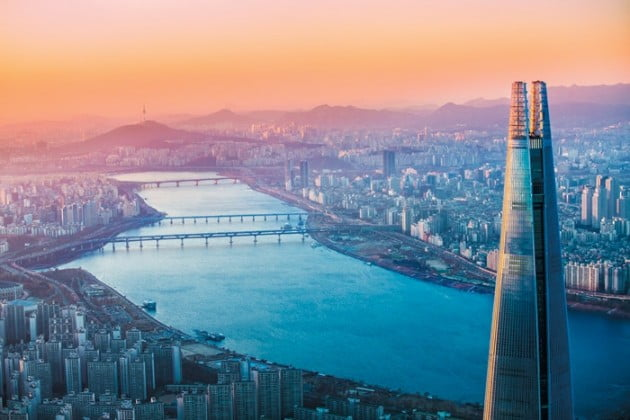

In [ ]:
# content image 확인
content_img

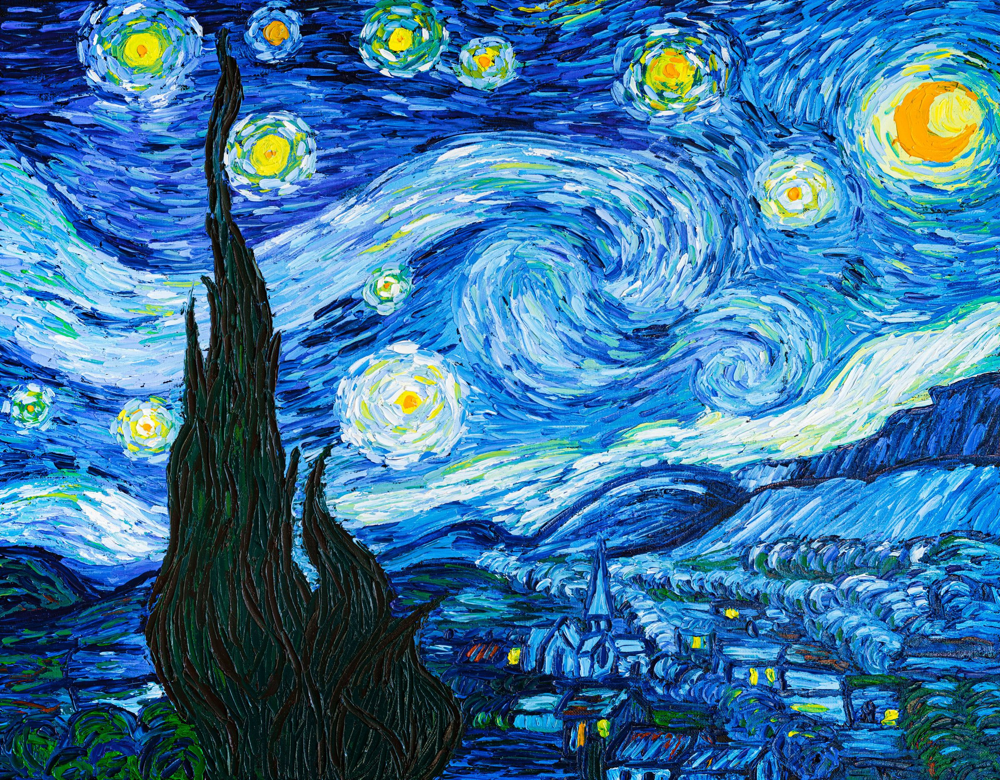

In [ ]:
# style image 확인
style_img

#### transformation 적용하기

In [ ]:
import torchvision.transforms as transforms

h, w = 256, 256
mean_rgb = (0.485, 0.456, 0.406)
std_rgb = (0.229, 0.224, 0.225)

transformer = transforms.Compose([
                transforms.Resize((h,w)),
                transforms.ToTensor(),
                transforms.Normalize(mean_rgb, std_rgb)
])

In [ ]:
# 이미지에 transformation 적용하기
content_tensor = transformer(content_img)
style_tensor = transformer(style_img)
print(content_tensor.shape, content_tensor.requires_grad)
print(style_tensor.shape, style_tensor.requires_grad)

torch.Size([3, 256, 256]) False
torch.Size([3, 256, 256]) False


In [ ]:
# transformation이 적용된 image 시각화하기
import torch

def imgtensor2pil(img_tensor):
    img_tensor_c = img_tensor.clone().detach()
    img_tensor_c *= torch.tensor(std_rgb).view(3, 1,1)
    img_tensor_c += torch.tensor(mean_rgb).view(3,1,1)
    img_tensor_c = img_tensor_c.clamp(0,1)
    img_pil = to_pil_image(img_tensor_c)
    return img_pil

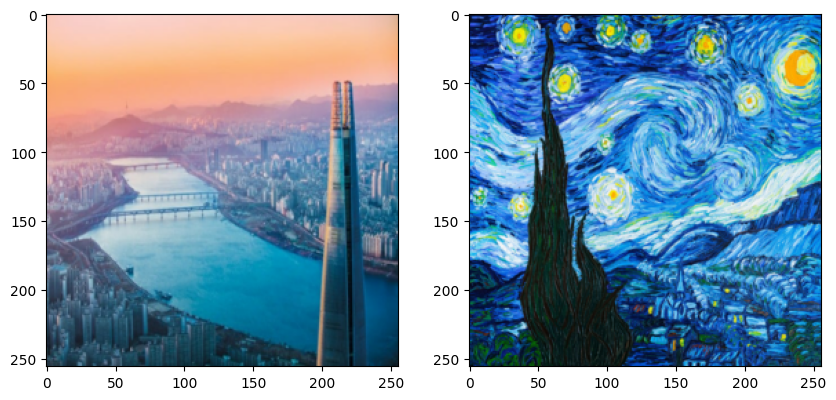

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline
from torchvision.transforms.functional import to_pil_image

plt.figure(figsize=(10,10))
plt.subplot(1,2,1)
plt.imshow(imgtensor2pil(content_tensor))
plt.subplot(1,2,2)
plt.imshow(imgtensor2pil(style_tensor))

#### pre-trained network

In [ ]:
# pretrained VGG19를 불러옵니다
import torchvision.models as models

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_vgg = models.vgg19(pretrained=True).features.to(device).eval()

# 파라미터를 freeze 합니다.
for param in model_vgg.parameters():
    param.requires_grad_(False)

/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG19_Weights.IMAGENET1K_V1`. You can also use `weights=VGG19_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth
100%|██████████| 548M/548M [00:05<00:00, 104MB/s]


#### 손실함수 정의하기

In [ ]:
# style loss와 content loss를 정의하기 위해
# 모델의 중간 feature를 얻은 후 Gram matrix를 계산해야 합니다.

# 모델의 중간 레이어의 출력값을 얻는 함수를 정의합니다.
def get_features(x, model, layers):
    features = {}
    for name, layer in enumerate(model.children()): # 0, conv
        x = layer(x)
        if str(name) in layers:
            features[layers[str(name)]] = x
    return features

Style Loss

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FbuDchH%2Fbtrmyi7pRnO%2FFeIZpIKGKZZZBjFBuk4AK0%2Fimg.png)

In [ ]:
# Gram matrix를 계산하는 함수를 정의합니다.
def gram_matrix(x):
    n, c, h, w = x.size()
    x = x.view(n, c, h*w)   # n x c x (hw)A
    gram = torch.bmm(x,x.permute(0,2,1)) # n x c x A *  n x A x c :: n x c x c
    # x = x.view(n*c, h*w)
    # gram = torch.mm(x,x.t()) # 행렬간 곱셈 수행

    return gram

In [ ]:
# style loss
def get_style_loss(pred_features, target_features, style_layers_dict):
    loss = 0
    for layer in style_layers_dict:
        pred_fea = pred_features[layer]
        pred_gram = gram_matrix(pred_fea)
        n, c, h, w = pred_fea.shape
        target_gram = gram_matrix(target_features[layer])
        layer_loss = style_layers_dict[layer] * F.mse_loss(pred_gram, target_gram)
        loss += layer_loss / (n*c*h*w)
    return loss

Contents loss

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2F6qUJd%2Fbtrmzjye1S5%2Fx58dwxKHYBokAUak7VRgz1%2Fimg.png)

In [ ]:
# content loss를 계산하는 함수를 정의합니다.
import torch.nn.functional as F

def get_content_loss(pred_features, target_features, layer):
    target = target_features[layer]
    pred = pred_features[layer]
    loss = F.mse_loss(pred, target)
    return loss

![](https://blog.kakaocdn.net/dn/o3UNh/btqt3HFMk85/OyWxQik5b31pSdOlqVqDE0/img.png)

어떻게 연결?

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FcPH0KZ%2FbtrmGgzK9yd%2FxT5n0ywrCX1dLZcuBomWr0%2Fimg.png)

In [ ]:
# content와 style image를 위한 feature를 얻습니다.
feature_layers = {'0': 'conv1_1',
                  '5': 'conv2_1',
                  '10': 'conv3_1',
                  '19': 'conv4_1',
                  '21': 'conv4_2',
                  '28': 'conv5_1'}

con_tensor = content_tensor.unsqueeze(0).to(device)
sty_tensor = style_tensor.unsqueeze(0).to(device)

content_features = get_features(con_tensor, model_vgg, feature_layers)
style_features = get_features(sty_tensor, model_vgg, feature_layers)

In [ ]:
# content feature를 확인합니다.
for key in content_features.keys():
    print(content_features[key].shape)

torch.Size([1, 64, 256, 256])
torch.Size([1, 128, 128, 128])
torch.Size([1, 256, 64, 64])
torch.Size([1, 512, 32, 32])
torch.Size([1, 512, 32, 32])
torch.Size([1, 512, 16, 16])


#### optimizer 정의하기

In [ ]:
# content tensor을 복사한 input tensor을 생성합니다.
input_tensor = con_tensor.clone().requires_grad_(True)

# optimizer를 정의합니다.
from torch import optim
optimizer = optim.Adam([input_tensor], lr=0.01)

#### 학습

In [ ]:
# 하이퍼파라미터를 정의합니다
num_epochs = 300
content_weight = 1e1
style_weight = 1e2
content_layer = 'conv4_2'
style_layers_dict = {'conv1_1':0.75,
                     'conv2_1':0.5,
                     'conv3_1':0.25,
                     'conv4_1':0.25,
                     'conv5_1':0.25}

In [ ]:
# style transfer
for epoch in range(num_epochs+1):
    optimizer.zero_grad()
    input_features = get_features(input_tensor, model_vgg, feature_layers) # feature_layers에 해당하는 layer의 출력값 얻기
    content_loss = get_content_loss(input_features, content_features, content_layer) #
    style_loss = get_style_loss(input_features, style_features, style_layers_dict)
    neural_loss = content_weight * content_loss + style_weight * style_loss
    neural_loss.backward(retain_graph=True)
    optimizer.step()
    if epoch % 100 == 0:
        print('epoch {}, content loss: {:.2}, style loss: {:.2}'.format(epoch, content_loss, style_loss))

epoch 0, content loss: 0.0, style loss: 4.6e+02
epoch 100, content loss: 9.4, style loss: 2.6e+01
epoch 200, content loss: 1e+01, style loss: 7.5
epoch 300, content loss: 9.9, style loss: 4.6


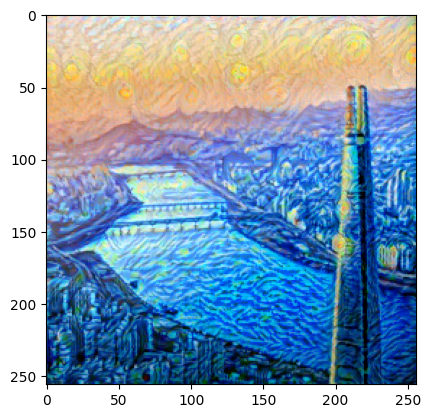

In [ ]:
# 결과 시각화
plt.imshow(imgtensor2pil(input_tensor[0].cpu()))

## [2교시] GAN: General Adversarial Network

논문: https://proceedings.neurips.cc/paper_files/paper/2014/hash/5ca3e9b122f61f8f06494c97b1afccf3-Abstract.html

거짓말쟁이와 진짜를 가려라!!!

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FWlCwU%2FbtrHKdREkbz%2FbsysnUDZzbB5AgGhhG0ZTK%2Fimg.png)

- Generator network: Random noise로부터 그럴싸한 이미지(Fake Images)를 만들어내는 네트워크
- Discriminator network: Real Images와 fake images를 비교하여 무엇이 fake 인지 찾아내는 네트워크
- 서로가 서로를 속이는 게임


수식으로 설명하는 GAN의 원리
![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2F3xpBe%2FbtrHK05Ms86%2FwusfIQEgAeF531ckjhlKA0%2Fimg.png)

> 용어: generator = G, G의 parameter = θ, discriminator = D, D의 parameter = ϕ, z = random noise. label = 실제 데이터(1) vs 가짜 데이터(0).

- Dϕ(x): ϕ파라미터를 가진 D가 x를 무엇이라 분류할 것인가? 0~1
- Gθ(z): θ파라미터를 가진 G가 노이즈(z)로부터 생성한 이미지 (Gθ(z))
- Dϕ(Gθ(z)): ϕ파라미터를 가진 D가 생성된 이미지(Gθ(z))를 무엇으로 분류할 것인가? 0~1


---


1. Discriminator의 목적
- Dϕ(x)를 1, 실제로 판단.
- Dϕ(Gθ(z))를 0, 가짜로 판단.

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fdphp5j%2FbtrHK0SfRYv%2F7UwL3cbqnmHktpAj9RIRD1%2Fimg.png)


>Discriminator는 위 식에서, D(x)를 최대한 1에 가깝게 만들고, D(
G(z))를 최대한 0에 가깝게 만듦으로써 objective function을 최대화하는 것을 목적으로 한다. 여기서 x는 실제 데이터이고, z는 가짜 데이터를 만드는 분포이다. 그러므로 D(x)를 최대한 1에 가깝게 만듦으로써 실제 데이터를 1로 분류하고, D(G(z))를 최대한 0에 가깝게 만듦으로써 가짜 데이터를 0으로 분류하도록 discriminator를 학습하는 것이다.


---
2. Generator의 목적
- Dϕ(x)를 0, 가짜로 판단.
- Dϕ(Gθ(z))를 1, 실제로 판단.

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FOtThm%2FbtrHNLz3ksl%2FX7CMxm5DX0WU7OcKv2KObk%2Fimg.png)

>Generator는 위 식에서, D(G(z))를 최대한 1에 가깝게 만듦으로써, objective function을 최소화하는 것을 목적으로 한다. D(G(z))를 최대한 1에 가깝게 만드는 것을 다시 말하면, discriminator가 가짜 데이터를 1로 분류하도록 속일 수 있는, 최대한 실제 데이터와 가까운 가짜 데이터를 만드는 방향으로 generator를 학습하는 것이다.



단, Generator가 잘 학습이 안된다.

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FbK9Zzh%2FbtrHJZ0AftZ%2FczjRhaMOGLivkI4Gp0XsD1%2Fimg.png)

> 함수를 조금 바꿈


![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FbZ9GeL%2FbtrHK1cBbeL%2F1TKsQOKzKfzGdxWZXQsaM1%2Fimg.png)

이유는 본 그래프에서 보는 것과 같이, log(1-D)의 로스가 클 때, 미분이 작아서 학습이 잘 안됨!




In [ ]:
import os
import torch
import torchvision
import torch.nn as nn
from torchvision import transforms
from torchvision.utils import save_image


# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Hyper-parameters
latent_size = 64
hidden_size = 256
image_size = 784
num_epochs = 200
batch_size = 100
sample_dir = 'samples'

# Create a directory if not exists
if not os.path.exists(sample_dir):
    os.makedirs(sample_dir)

# Image processing
# transform = transforms.Compose([
#                 transforms.ToTensor(),
#                 transforms.Normalize(mean=(0.5, 0.5, 0.5),   # 3 for RGB channels
#                                      std=(0.5, 0.5, 0.5))])
transform = transforms.Compose([
                transforms.ToTensor(),
                transforms.Normalize(mean=[0.5],   # 1 for greyscale channels
                                     std=[0.5])])

# MNIST dataset
mnist = torchvision.datasets.MNIST(root='../../data/',
                                   train=True,
                                   transform=transform,
                                   download=True)

# Data loader
data_loader = torch.utils.data.DataLoader(dataset=mnist,
                                          batch_size=batch_size,
                                          shuffle=True)

# Discriminator
D = nn.Sequential(
    nn.Linear(image_size, hidden_size),
    nn.LeakyReLU(0.2),
    nn.Linear(hidden_size, hidden_size),
    nn.LeakyReLU(0.2),
    nn.Linear(hidden_size, 1),
    nn.Sigmoid())

# Generator
G = nn.Sequential(
    nn.Linear(latent_size, hidden_size),
    nn.ReLU(),
    nn.Linear(hidden_size, hidden_size),
    nn.ReLU(),
    nn.Linear(hidden_size, image_size),
    nn.Tanh())

# Device setting
D = D.to(device)
G = G.to(device)


# Binary cross entropy loss and optimizer
criterion = nn.BCELoss()
d_optimizer = torch.optim.Adam(D.parameters(), lr=0.0002)
g_optimizer = torch.optim.Adam(G.parameters(), lr=0.0002)


def denorm(x):
    out = (x + 1) / 2
    return out.clamp(0, 1)

def reset_grad(): # 가중치를 0으로 초기화
    d_optimizer.zero_grad()
    g_optimizer.zero_grad()

dx_epoch = []
dgx_epoch = []
total_step = len(data_loader)
for epoch in range(num_epochs):
    for i, (images, _) in enumerate(data_loader):
        images = images.reshape(batch_size, -1).to(device)

        # Create the labels which are later used as input for the BCE loss
        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)

        # ================================================================== #
        #                      Train the discriminator                       #
        # ================================================================== #

        # Compute BCE_Loss using real images where BCE_Loss(x, y): - y * log(D(x)) - (1-y) * log(1 - D(x))
        # Second term of the loss is always zero since real_labels == 1
        outputs = D(images)
        d_loss_real = criterion(outputs, real_labels)
        real_score = outputs

        # Compute BCELoss using fake images
        # First term of the loss is always zero since fake_labels == 0
        z = torch.randn(batch_size, latent_size).to(device)
        fake_images = G(z)
        outputs = D(fake_images)
        d_loss_fake = criterion(outputs, fake_labels)
        fake_score = outputs

        # Backprop and optimize
        d_loss = d_loss_real + d_loss_fake
        reset_grad()
        d_loss.backward()
        d_optimizer.step()

        # ================================================================== #
        #                        Train the generator                         #
        # ================================================================== #

        # Compute loss with fake images
        z = torch.randn(batch_size, latent_size).to(device)
        fake_images = G(z)
        outputs = D(fake_images)

        g_loss = criterion(outputs, real_labels)

        # Backprop and optimize
        reset_grad()
        g_loss.backward()
        g_optimizer.step()

        if (i+1) % 200 == 0:
            print('Epoch [{}/{}], Step [{}/{}], d_loss: {:.4f}, g_loss: {:.4f}, D(x): {:.2f}, D(G(z)): {:.2f}'
                  .format(epoch, num_epochs, i+1, total_step, d_loss.item(), g_loss.item(),
                          real_score.mean().item(), fake_score.mean().item()))
    dx_epoch.append(real_score.mean().item())
    dgx_epoch.append(fake_score.mean().item())
    # real image 저장
    if (epoch+1) == 1:
        images = images.reshape(images.size(0), 1, 28, 28)
        save_image(denorm(images), os.path.join(sample_dir, 'real_images.png'))

    # 생성된 이미지 저장
    fake_images = fake_images.reshape(fake_images.size(0), 1, 28, 28)
    save_image(denorm(fake_images), os.path.join(sample_dir, 'fake_images-{}.png'.format(epoch+1)))

# 생성자, 판별자 각각 모델 저장
torch.save(G.state_dict(), 'G.ckpt')
torch.save(D.state_dict(), 'D.ckpt')
# Save the model checkpoints
torch.save(G.state_dict(), 'G.ckpt')
torch.save(D.state_dict(), 'D.ckpt')

100%|██████████| 9912422/9912422 [00:00<00:00, 134461761.91it/s]


Extracting ../../data/MNIST/raw/train-images-idx3-ubyte.gz to ../../data/MNIST/raw



100%|██████████| 28881/28881 [00:00<00:00, 20625863.07it/s]


Extracting ../../data/MNIST/raw/train-labels-idx1-ubyte.gz to ../../data/MNIST/raw



100%|██████████| 1648877/1648877 [00:00<00:00, 44553404.99it/s]


Extracting ../../data/MNIST/raw/t10k-images-idx3-ubyte.gz to ../../data/MNIST/raw



100%|██████████| 4542/4542 [00:00<00:00, 13021550.76it/s]

Extracting ../../data/MNIST/raw/t10k-labels-idx1-ubyte.gz to ../../data/MNIST/raw



Epoch [0/200], Step [200/600], d_loss: 0.0315, g_loss: 4.3498, D(x): 0.99, D(G(z)): 0.02
Epoch [0/200], Step [400/600], d_loss: 0.0535, g_loss: 5.8018, D(x): 0.99, D(G(z)): 0.04
Epoch [0/200], Step [600/600], d_loss: 0.1656, g_loss: 4.2821, D(x): 0.94, D(G(z)): 0.08
Epoch [1/200], Step [200/600], d_loss: 0.0437, g_loss: 5.0094, D(x): 0.98, D(G(z)): 0.02
Epoch [1/200], Step [400/600], d_loss: 0.1254, g_loss: 4.4429, D(x): 0.95, D(G(z)): 0.02
Epoch [1/200], Step [600/600], d_loss: 0.0929, g_loss: 4.4435, D(x): 0.95, D(G(z)): 0.03
Epoch [2/200], Step [200/600], d_loss: 0.4543, g_loss: 4.6069, D(x): 0.86, D(G(z)): 0.16
Epoch [2/200], Step [400/600], d_loss: 0.4100, g_loss: 3.0444, D(x): 0.86, D(G(z)): 0.09
Epoch [2/200], Step [600/600], d_loss: 0.2371, g_loss: 3.9284, D(x): 0.95, D(G(z)): 0.14
Epoch [3/200], Step [200/600], d_loss: 0.3363, g_loss: 3.5944, D(x): 0.91, D(G(z)): 0.16
Epoch [3/200], Step [400/600], d_loss: 0.5038, g_loss: 3.1702, D(x): 0.79, D(G(z)): 0.07
Epoch [3/200], Step [

In [ ]:
from matplotlib import pyplot as plt

# plot
plt.figure(figsize = (12, 8))
plt.xlabel('epoch')
plt.ylabel('score')
x = np.arange(num_epochs)
plt.plot(x, dx_epoch, 'g', label='D(x)')
plt.plot(x, dgx_epoch, 'b', label='D(G(z))')
plt.legend()
plt.show()

NameError: ignored

#### GAN의 문제점

***mode-collapse***: Mode-collapse는 generator와 discriminator 중 하나가 너무 학습이 잘 돼서 다른 하나의 학습이 진행되지 않는 상태.

Example. Discriminator가 완벽: generator는 무슨짓을 해도 발전할 방법이 없음.



## [3교시] DCGAN


#### 개요

본 튜토리얼에서는 예제를 통해 DCGAN을 알아보겠습니다. 우리는 실제 유명인들의 사진들로 적대적 생성 신경망(GAN)을 학습시켜,
새로운 유명인의 사진을 만들어볼겁니다.
사용할 대부분의 코드는 [pytorch/examples](https://github.com/pytorch/examples)_ 의 DCGAN 구현에서 가져왔으며,
본 문서는 구현에 대한 설명과 함께, 어째서 이 모델이 작동하는지에 대해 설명을 해줄 것입니다.
처음 읽었을때는, 실제로 모델에 무슨일이 일어나고 있는지에 대해 이해하는 것이 조금 시간을 소요할 수 있으나,
그래도 GAN에 대한 사전지식이 필요하지는 않으니 걱정하지 않으셔도 됩니다.
추가로, GPU 1-2개를 사용하는 것이 시간절약에 도움이 될겁니다. 그럼 처음부터 천천히 시작해봅시다!

## 적대적 생성 신경망(Generative Adversarial Networks)

### 그래서 GAN이 뭘까요?

GAN이란 학습 데이터들의 분포를 학습해, 같은 분포에서 새로운 데이터를 생성할 수 있도록 DL 모델을 학습시키는 프레임워크입니다.
2014년 Ian Goodfellow가 개발했으며, [Generative Adversarial
Nets](https://papers.nips.cc/paper/5423-generative-adversarial-nets.pdf)_ 논문에서 처음 소개되었습니다.
GAN은 *생성자* 와 *구분자* 로 구별되는 두가지 모델을 가지고 있는것이 특징입니다.
생성자의 역할은 실제 이미지로 착각되도록 정교한 이미지를 만드는 것이고,
구분자의 역할은 이미지를 보고 생성자에 의해 만들어진 이미지인지 실제 이미지인지 알아내는 것입니다.
모델을 학습하는 동안, 생성자는 더 진짜같은 가짜 이미지를 만들어내며 구분자를 속이려 하고,
구분자는 더 정확히 가짜/진짜 이미지를 구별할 수 있도록 노력합니다.
이 ‘경찰과 도둑’ 게임은, 생성자가 학습 데이터들에서 직접 가져온 것처럼 보일정도로 완벽한 이미지를 만들어내고,
구분자가 생성자에서 나온 이미지를 50%의 확률로 가짜 혹은 진짜로 판별할 때, 균형상태에 도달하게 됩니다.

그럼 이제부터 본 튜토리얼에서 사용할 표기들을 구분자부터 정의해보겠습니다. $x$ 는 이미지로 표현되는 데이터로 두겠습니다.
$D(x)$ 는 구분자 신경망이고, 실제 학습데이터에서 가져온 $x$ 를 통과시켜 상수(scalar) 확률값을 결과로 출려합니다.
이때, 우리는 이미지 데이터를 다루고 있으므로, $D(x)$ 에는 3x64x64크기의 CHW 데이터가 입력됩니다. 직관적으로 볼때,
$D(x)$ 는 $x$ 가 학습데이터에서 가져온 것일 때 출력이 크고, 생성자가 만들어낸 $x$ 일때 작을 것입니다.
$D(x)$ 는 전통적인 이진 분류기(binary classification)으로도 생각될 수 있습니다.

이번엔 생성자의 표기들을 확인해봅시다. $z$ 를 정규분포에서 뽑은 잠재공간 벡터(laten space vector)라고 하겠습니다
(번역 주. laten space vector는 쉽게 생각해 정규분포를 따르는 n개의 원소를 가진 vector라 볼 수 있습니다.
다르게 얘기하면 정규분포에서 n개의 원소를 추출한 것과 같습니다). $G(z)$ 는 $z$
벡터를 원하는 데이터 차원으로 대응시키는 신경망으로 둘 수 있습니다. 이때 $G$ 의 목적은 $p_{data}$
에서 얻을 수 있는 학습 데이터들의 분포를 추정하여, 모사한 $p_g$ 의 분포를 이용해 가짜 데이터들을 만드는 것입니다.

이어서, $D(G(z))$ 는 $G$ 가 출력한 결과물이 실제 이미지일 0~1사이의 상수의 확률값입니다.
[Goodfellow의 논문](https://papers.nips.cc/paper/5423-generative-adversarial-nets.pdf)_
에 기술되어 있듯, $D$ 가 이미지의 참/거짓을 정확히 판별할 확률인 $logD(x)$를 최대화 시키고,
$G$ 에서 생성한 이미지를 $D$ 가 가짜로 판별할 확률인
($log(1-D(G(z)))$)를 최소화 시키려는 점에서, $D$ 와 $G$ 는 최대최소(minmax)게임을 하는 것과 같습니다.
논문에 따르면, GAN의 손실함수는 아래와 같습니다.

\begin{align}\underset{G}{\text{min}} \underset{D}{\text{max}}V(D,G) = \mathbb{E}_{x\sim p_{data}(x)}\big[logD(x)\big] + \mathbb{E}_{z\sim p_{z}(z)}\big[log(1-D(G(z)))\big]\end{align}

이론적으로는, 이 최대최소게임은 $p_g = p_{data}$ 이고, 구분자에 입력된 데이터가 1/2의 무작위 확률로 참/거짓이 판별될때 해답에 이릅니다.
하지만 GAN의 수렴 이론은 아직도 활발히 연구가 진행중이고, 현실에서의 모델들은 이론적인 최적 상태에 도달하지 않는 경우도 많습니다.

### 그렇다면 DCGAN은 뭘까요?

DCGAN은 위에서 기술한 GAN에서 직접적으로 파생된 모델로, 생성자와 구분자에서
합성곱 신경망(convolution)과 전치 합성곱 신경망(convolution-transpose)을 사용했다는 것이 차이점입니다
Radford와 그 외가 저술한 [Unsupervised Representation Learning With
Deep Convolutional Generative Adversarial
Networks](https://arxiv.org/pdf/1511.06434.pdf)_ 논문에서 처음 모델이 소개되었고, 지금은 대부분의 GAN모델이
DCGAN을 기반으로 만들어지는 중입니다. 이전 GAN과 모델의 구조가 실제로 어떻게 다른지 확인을 해보자면, 먼저 구분자에서는
[convolution](https://pytorch.org/docs/stable/nn.html#torch.nn.Conv2d)_
계층, [batch
norm](https://pytorch.org/docs/stable/nn.html#torch.nn.BatchNorm2d)_
계층, 그리고
[LeakyReLU](https://pytorch.org/docs/stable/nn.html#torch.nn.LeakyReLU)_
활성함수가 사용되었습니다. 클래식한 GAN과 마찬가지로, 구분자의 입력 데이터는 3x64x64 의 이미지이고,
출력값은 입력 데이터가 실제 데이터일 0~1사이의 확률값입니다.
다음으로, 생성자는
[convolutional-transpose](https://pytorch.org/docs/stable/nn.html#torch.nn.ConvTranspose2d)_
계층, 배치 정규화(batch norm) 계층, 그리고
[ReLU](https://pytorch.org/docs/stable/nn.html#relu)_ 활성함수가 사용되었습니다. 입력값은 역시나
정규분포에서 추출한 잠재공간 벡터 $z$ 이고, 출력값은 3x64x64 RGB 이미지입니다. 이때,
전치 합성곱 신경망은 잠재공간 벡터로 하여금 이미지와 같은 차원을 갖도록 변환시켜주는 역할을 합니다 (번역 주. 전치 합성곱 신경망은
합성곱 신경망의 반대적인 개념이라 이해하면 쉽습니다. 입력된 작은 CHW 데이터를 가중치들을 이용해 더 큰 CHW로 업샘플링해주는 계층입니다).
논문에서는 각종 최적화 방법이나 손실함수의 계산, 모델의 가중치 초기화 방법등에 관한 추가적인 정보들도 적어두었는데,
이 부분은 다음 섹션에서 설명하도록 하겠습니다.



In [ ]:
from __future__ import print_function
#%matplotlib inline
import argparse
import os
import random
import torch
import torch.nn as nn
import torch.nn.parallel
import torch.backends.cudnn as cudnn
import torch.optim as optim
import torch.utils.data
import torchvision.datasets as dset
import torchvision.transforms as transforms
import torchvision.utils as vutils
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

# 코드 실행결과의 동일성을 위해 무작위 시드를 설정합니다
manualSeed = 999
#manualSeed = random.randint(1, 10000) # 만일 새로운 결과를 원한다면 주석을 없애면 됩니다
print("Random Seed: ", manualSeed)
random.seed(manualSeed)
torch.manual_seed(manualSeed)

Random Seed:  999


#### 설정값

몇 가지 설정값들을 정의해봅시다:

-  ``dataroot`` - 데이터셋 폴더의 경로입니다. 데이터셋에 관한건 다음 섹션에서
   더 자세히 설명하겠습니다.
-  ``workers`` - DataLoader에서 데이터를 불러올 때 사용할 쓰레드의 개수입니다.
-  ``batch_size`` - 학습에 사용할 배치 크기입니다. DCGAN에서는 128을 사용했습니다.
-  ``image_size`` - 학습에 사용되는 이미지의 크기입니다.
   본 문서에서는 64x64의 크기를 기본으로 하나, 만일 다른 크기의 이미지를 사용한다면
   D와 G의 구조 역시 변경되어야 합니다. 더 자세한 정보를 위해선
   [이곳](https://github.com/pytorch/examples/issues/70)_ 을 확인해 보세요.
-  ``nc`` - 입력 이미지의 색 채널개수입니다. RGB 이미지이기 때문에 3으로 설정합니다.
-  ``nz`` - 잠재공간 벡터의 원소들 개수입니다.
-  ``ngf`` - 생성자를 통과할때 만들어질 특징 데이터의 채널개수입니다.
-  ``ndf`` - 구분자를 통과할때 만들어질 특징 데이터의 채널개수입니다.
-  ``num_epochs`` - 학습시킬 에폭 수입니다. 오래 학습시키는 것이 대부분 좋은 결과를 보이지만, 당연히도 시간이 오래걸리는 것이 단점입니다.
-  ``lr`` - 모델의 학습률입니다. DCGAN에서 사용된대로 0.0002로 설정합니다.
-  ``beta1`` - Adam 옵티마이저에서 사용할 beta1 하이퍼파라미터 값입니다. 역시나 논문에서 사용한대로 0.5로 설정했습니다.
-  ``ngpu`` - 사용가능한 GPU의 번호입니다. 0으로 두면 CPU에서 학습하고, 0보다 큰 수로 설정하면 각 숫자가 가리키는 GPU로 학습시킵니다.




In [ ]:
# 데이터셋의 경로
dataroot = "data"

# dataloader에서 사용할 쓰레드 수
workers = 2

# 배치 크기
batch_size = 128

# 이미지의 크기입니다. 모든 이미지를 변환하여 64로 크기가 통일됩니다.
image_size = 64

# 이미지의 채널 수로, RGB 이미지이기 때문에 3으로 설정합니다.
nc = 3

# 잠재공간 벡터의 크기 (예. 생성자의 입력값 크기)
nz = 100

# 생성자를 통과하는 특징 데이터들의 채널 크기
ngf = 64

# 구분자를 통과하는 특징 데이터들의 채널 크기
ndf = 64

# 학습할 에폭 수
num_epochs = 5

# 옵티마이저의 학습률
lr = 0.0002

# Adam 옵티마이저의 beta1 하이퍼파라미터
beta1 = 0.5

# 사용가능한 gpu 번호. CPU를 사용해야 하는경우 0으로 설정하세요
ngpu = 1

In [ ]:
# 우리가 설정한 대로 이미지 데이터셋을 불러와 봅시다
# 먼저 데이터셋을 만듭니다
transform = transforms.Compose([
                transforms.ToTensor(),
                transforms.Normalize(mean=[0.5],   # 1 for greyscale channels
                                     std=[0.5])])

celeba = dset.VOCSegmentation(root=dataroot,
                    year='2007',
                    transforms=transform,
                    download=True)

Using downloaded and verified file: data/VOCtrainval_06-Nov-2007.tar
Extracting data/VOCtrainval_06-Nov-2007.tar to data


In [ ]:
!cp -r /content/data/VOCdevkit/VOC2007/JPEGImages /content/data/VOCdevkit/VOC2007/train

In [ ]:
!ls

data  sample_data


#### 데이터

본 튜토리얼에서 사용할 데이터는 [Celeb-A Faces
dataset](http://mmlab.ie.cuhk.edu.hk/projects/CelebA.html)_ 로, 해당 링크를 이용하거나 [Google
Drive](https://drive.google.com/drive/folders/0B7EVK8r0v71pTUZsaXdaSnZBZzg)_ 에서 데이터를 받을 수 있습니다.
데이터를 받으면 ``img_align_celeba.zip`` 라는 파일을 보게될 겁니다. 다운로드가 끝나면
``celeba`` 이라는 폴더를 새로 만들고, 해당 폴더에 해당 zip 파일을 압축해제 해주시면 됩니다.
압축 해제 후, 위에서 정의한 ``dataroot`` 변수에 방금 만든 ``celeba`` 폴더의 경로를 넣어주세요.
위의 작업이 끝나면 ``celeba`` 폴더의 구조는 다음과 같아야 합니다:

::

   /path/to/celeba
       -> img_align_celeba
           -> 188242.jpg
           -> 173822.jpg
           -> 284702.jpg
           -> 537394.jpg
              ...

이 과정들은 프로그램이 정상적으로 구동하기 위해서는 중요한 부분입니다.
이때 ``celeba`` 폴더 안에 다시 폴더를 두는 이유는,
``ImageFolder`` 클래스가 데이터셋의 최상위 폴더에 서브폴더를 요구하기 때문입니다.
이제 ``Dataset`` 과 ``DataLoader`` 의 설정을 끝냈습니다.
최종적으로 학습 데이터들을 시각화해봅시다.




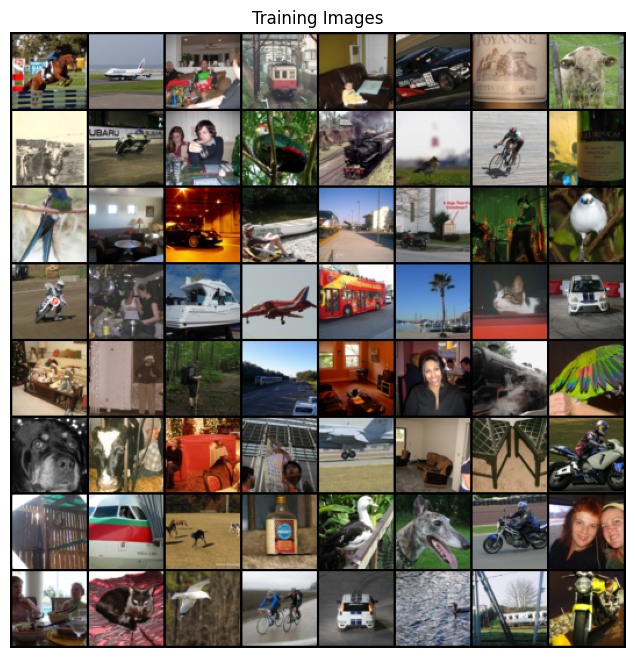

In [ ]:
# celeba = dset.SBDataset(root=dataroot,
#                     transforms=transform,
#                     download=True)

# Data loader
# data_loader = torch.utils.data.DataLoader(dataset=cifar10,
#                                           batch_size=batch_size,
#                                           shuffle=True)

dataset = dset.ImageFolder(root='/content/data/VOCdevkit/VOC2007/train',
                           transform=transforms.Compose([
                               transforms.Resize(image_size),
                               transforms.CenterCrop(image_size),
                               transforms.ToTensor(),
                               transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
                           ]))
# dataloader를 정의해봅시다
dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size,
                                         shuffle=True, num_workers=workers)

# GPU 사용여부를 결정해 줍니다
device = torch.device("cuda:0" if (torch.cuda.is_available() and ngpu > 0) else "cpu")

# 학습 데이터들 중 몇가지 이미지들을 화면에 띄워봅시다
real_batch = next(iter(dataloader))
plt.figure(figsize=(8,8))
plt.axis("off")
plt.title("Training Images")
plt.imshow(np.transpose(vutils.make_grid(real_batch[0].to(device)[:64], padding=2, normalize=True).cpu(),(1,2,0)))

#### 구현

모델의 설정값들과 데이터들이 준비되었기 때문에, 드디어 모델의 구현으로
들어갈 수 있을 것 같습니다. 먼저 가중치 초기화에 대해 이야기 해보고,
순서대로 생성자, 구분자, 손실 함수, 학습 방법들을 알아보겠습니다.

###### 가중치 초기화

DCGAN 논문에서는, 평균이 0( ``mean=0`` )이고 분산이 0.02( ``stdev=0.02`` )인
정규분포을 시용해, 구분자와 생성자 모두 무작위 초기화를 진행하는 것이 좋다고 합니다.
``weights_init`` 함수는 매개변수로 모델을 입력받아,
모든 합성곱 계층, 전치 합성곱 계층, 배치 정규화 계층을, 위에서 말한 조건대로
가중치들을 다시 초기화 시킵니다. 이 함수는 모델이 만들어지자 마자 바로 적용을
시키게 됩니다.



In [ ]:
# ``netG`` 와 ``netD`` 에 적용시킬 커스텀 가중치 초기화 함수
def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

### 생성자

생성자 $G$ 는 잠재 공간 벡터 $z$ 를, 데이터 공간으로
변환시키도록 설계되었습니다. 우리에게 데이터라 함은 이미지이기 때문에,
$z$ 를 데이터공간으로 변환한다는 뜻은, 학습이미지와 같은 사이즈를 가진
RGB 이미지를 생성하는것과 같습니다 (예. 3x64x64).
실제 모델에서는 스트라이드(stride) 2를 가진 전치 합성곱 계층들을 이어서 구성하는데,
각 전치 합성곱 계층 하나당 2차원 배치 정규화 계층과 relu 활성함수를 한 쌍으로 묶어서 사용합니다.
생성자의 마지막 출력 계층에서는 데이터를 tanh 함수에 통과시키는데,
이는 출력 값을 $[-1,1]$ 사이의 범위로 조정하기 위해서 입니다.
이때 배치 정규화 계층을 주목할 필요가 있는데, DCGAN 논문에 의하면,
이 계층이 경사하강법(gradient-descent)의 흐름에 중요한 영향을 미치는 것으로 알려져 있습니다.
아래의 그림은 DCGAN 논문에서 가져온 생성자의 모델 아키텍쳐입니다.

.. figure:: /_static/img/dcgan_generator.png
   :alt: dcgan_generator

우리가 설정값 섹션에서 정의한 값들이 (``nz``, ``ngf``, 그리고
``nc``) 생성자 모델 아키텍쳐에 어떻게 영향을 끼치는지 주목해주세요. ``nz`` 는 z 입력 벡터의
길이, ``ngf`` 는 생성자를 통과하는 특징 데이터의 크기, 그리고 ``nc`` 는 출력 이미지의
채널 개수입니다 (RGB 이미지이기 때문에 3으로 설정을 했습니다).
아래는 생성자의 코드입니다.




In [ ]:
# 생성자 코드

class Generator(nn.Module):
    def __init__(self, ngpu):
        super(Generator, self).__init__()
        self.ngpu = ngpu
        self.main = nn.Sequential(
            # 입력데이터 Z가 가장 처음 통과하는 전치 합성곱 계층입니다.
            nn.ConvTranspose2d( nz, ngf * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(ngf * 8),
            nn.ReLU(True),
            # 위의 계층을 통과한 데이터의 크기. ``(ngf*8) x 4 x 4``
            nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),
            # 위의 계층을 통과한 데이터의 크기. ``(ngf*4) x 8 x 8``
            nn.ConvTranspose2d( ngf * 4, ngf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),
            # 위의 계층을 통과한 데이터의 크기. ``(ngf*2) x 16 x 16``
            nn.ConvTranspose2d( ngf * 2, ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),
            # 위의 계층을 통과한 데이터의 크기. ``(ngf) x 32 x 32``
            nn.ConvTranspose2d( ngf, nc, 4, 2, 1, bias=False),
            nn.Tanh()
            # 위의 계층을 통과한 데이터의 크기. ``(nc) x 64 x 64``
        )

    def forward(self, input):
        return self.main(input)

좋습니다. 이제 우리는 생성자의 인스턴스를 만들고 ``weights_init``
함수를 적용시킬 수 있습니다. 모델의 인스턴스를 출력해서 생성자가
어떻게 구성되어있는지 확인해봅시다.




In [ ]:
# 생성자를 만듭니다
netG = Generator(ngpu).to(device)

# 필요한 경우 multi-GPU를 설정 해주세요
if (device.type == 'cuda') and (ngpu > 1):
    netG = nn.DataParallel(netG, list(range(ngpu)))

# 모든 가중치의 평균을 0( ``mean=0`` ), 분산을 0.02( ``stdev=0.02`` )로 초기화하기 위해
# ``weight_init`` 함수를 적용시킵니다
netG.apply(weights_init)

# 모델의 구조를 출력합니다
print(netG)

Generator(
  (main): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (13): Tanh()
  )
)


### 구분자

앞서 언급했듯, 구분자 $D$ 는 입력 이미지가 진짜 이미지인지 (혹은 반대로 가짜 이미지인지)
판별하는 전통적인 이진 분류 신경망으로 볼 수 있습니다. 이때 $D$ 는
3x64x64 이미지를 입력받아, Conv2d, BatchNorm2d, 그리고 LeakyReLU 계층을 통과시켜
데이터를 가공시키고, 마지막 출력에서 Sigmoid 함수를 이용하여
0~1 사이의 확률값으로 조정합니다. 이 아키텍쳐는 필요한 경우 더 다양한 레이어를 쌓을 수 있지만,
배치 정규화와 LeakyReLU, 특히 보폭이 있는 (strided) 합성곱 계층을
사용하는 것에는 이유가 있습니다.
DCGAN 논문에서는 보폭이 있는 합성곱 계층을 사용하는 것이 신경망 내에서 스스로의
풀링(Pooling) 함수를 학습하기 때문에, 데이터를 처리하는 과정에서 직접적으로 풀링 계층( MaxPool or AvgPooling)을
사용하는 것보다 더 유리하다고 합니다. 또한 배치 정규화와 leaky relu 함수는 학습과정에서
$G$ 와 $D$ 가 더 효과적인 경사도(gradient)를 얻을 수 있습니다.




In [ ]:
# 구분자 코드

class Discriminator(nn.Module):
    def __init__(self, ngpu):
        super(Discriminator, self).__init__()
        self.ngpu = ngpu
        self.main = nn.Sequential(
            # 입력 데이터의 크기는 ``(nc) x 64 x 64`` 입니다
            nn.Conv2d(nc, ndf, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # 위의 계층을 통과한 데이터의 크기. ``(ndf) x 32 x 32``
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),
            # 위의 계층을 통과한 데이터의 크기. ``(ndf*2) x 16 x 16``
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),
            # 위의 계층을 통과한 데이터의 크기. ``(ndf*4) x 8 x 8``
            nn.Conv2d(ndf * 4, ndf * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 8),
            nn.LeakyReLU(0.2, inplace=True),
            # 위의 계층을 통과한 데이터의 크기. ``(ndf*8) x 4 x 4``
            nn.Conv2d(ndf * 8, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, input):
        return self.main(input)

이제 우리는 생성자에 한 것처럼 구분자의 인스턴스를 만들고,
``weights_init`` 함수를 적용시킨 다음, 모델의 구조를 출력해볼 수 있습니다.




In [ ]:
# 구분자를 만듭니다
netD = Discriminator(ngpu).to(device)

# 필요한 경우 multi-GPU를 설정 해주세요
if (device.type == 'cuda') and (ngpu > 1):
    netD = nn.DataParallel(netD, list(range(ngpu)))

# 모든 가중치의 평균을 0( ``mean=0`` ), 분산을 0.02( ``stdev=0.02`` )로 초기화하기 위해
# ``weight_init`` 함수를 적용시킵니다
netD.apply(weights_init)

# 모델의 구조를 출력합니다
print(netD)

Discriminator(
  (main): Sequential(
    (0): Conv2d(3, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (6): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.2, inplace=True)
    (8): Conv2d(256, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (9): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): LeakyReLU(negative_slope=0.2, inplace=True)
    (11): Conv2d(512, 1, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (12): Sigmoid()
  )
)


### 손실함수와 옵티마이저

$D$ 와 $G$ 의 설정을 끝냈으니, 이제 손실함수와 옵티마이저를 정하여
학습을 구체화시킬 시간입니다. 손실함수로는 Binary Cross Entropy loss
([BCELoss](https://pytorch.org/docs/stable/generated/torch.nn.BCELoss.html#torch.nn.BCELoss)_)
를 사용할겁니다. 해당함수는 아래의 식으로 파이토치에 구현되어 있습니다:

\begin{align}\ell(x, y) = L = \{l_1,\dots,l_N\}^\top, \quad l_n = - \left[ y_n \cdot \log x_n + (1 - y_n) \cdot \log (1 - x_n) \right]\end{align}

이때, 위의 함수가 로그함수 요소를 정의한 방식을 주의깊게 봐주세요 (예. $log(D(x))$ 와
$log(1-D(G(z)))$). 우린 $y$ 을 조정을 조정하여, BCE 함수에서
사용할 요소를 고를 수 있습니다.
이 부분은 이후에 서술할 학습 섹션에서 다루겠지만, 어떻게 $y$ 를 이용하여
우리가 원하는 요소들만 골라낼 수 있는지 이해하는 것이 먼저입니다 (예. GT labels).

좋습니다. 다음으로 넘어가겠습니다. 참 라벨 (혹은 정답)은 1로 두고, 거짓 라벨 (혹은 오답)은 0으로
두겠습니다. 각 라벨의 값을 정한건 GAN 논문에서 사용된 값들로, GAN을 구성할때의 관례라 할
수 있습니다. 방금 정한 라벨 값들은 추후에 손실값을 계산하는 과정에서 사용될겁니다.
마지막으로, 서로 구분되는 두 옵티마이저를 구성하겠습니다. 하나는 $D$ 를 위한 것,
다른 하나는 $G$ 를 위한 것입니다. DCGAN에 서술된 대로, 두 옵티마이저는 모두 Adam을 사용하고,
학습률은 0.0002, Beta1 값은 0.5로 둡니다. 추가적으로, 학습이 진행되는 동안 생성자의 상태를 알아보기 위하여,
프로그램이 끝날때까지 고정된 잠재공간 벡터를 생성하겠습니다 (예. fixed_noise).
이 벡터들 역시 가우시안 분포에서 추출합니다. 학습 과정을 반복하면서  $G$ 에 주기적으로 같은 잠재공간 벡터를
입력하면, 그 출력값을 기반으로 생성자의 상태를 확인 할 수 있습니다.




In [ ]:
# ``BCELoss`` 함수의 인스턴스를 초기화합니다
criterion = nn.BCELoss()

# 생성자의 학습상태를 확인할 잠재 공간 벡터를 생성합니다
fixed_noise = torch.randn(64, nz, 1, 1, device=device)

# 학습에 사용되는 참/거짓의 라벨을 정합니다
real_label = 1.
fake_label = 0.

# G와 D에서 사용할 Adam옵티마이저를 생성합니다
optimizerD = optim.Adam(netD.parameters(), lr=lr, betas=(beta1, 0.999))
optimizerG = optim.Adam(netG.parameters(), lr=lr, betas=(beta1, 0.999))

### 학습

드디어 최종입니다. GAN 프레임워크에 필요한 부분들은 모두 가졌으니,
실제 모델을 학습시키는 방법을 알아보겠습니다. 주의를 기울일 것은, GAN을 학습시키는 건
관례적인 기술들의 집합이기 때문에, 잘못된 하이퍼파라미터의 설정은
모델의 학습을 망가뜨릴 수 있습니다. 무엇이 잘못되었는지 알아내는 것 조차도 힘들죠.
그러한 이유로, 본 튜토리얼에서는 [Goodfellow’s paper](https://papers.nips.cc/paper/5423-generative-adversarial-nets.pdf)_
에서 서술된 Algorithm 1을 기반으로, [ganhacks](https://github.com/soumith/ganhacks)_ 에서 사용된 몇가지 괜찮은 테크닉들을
더할 것입니다. 앞서 몇번 설명했지만, 우리의 의도는 “진짜 혹은 가짜 이미지를 구성”하고,
$log(D(G(z)))$ 를 최대화하는 G의 목적함수를 최적화 시키는 겁니다. 학습과정은 크게 두가지로 나눕니다.
Part 1은 구분자를, Part 2는 생성자를 업데이트하는 과정입니다.

**Part 1 - 구분자의 학습**

구분자의 목적은 주어진 입력값이 진짜인지 가짜인지 판별하는 것임을 상기합시다.
Goodfellow의 말을 빌리자면, 구분자는 “변화도(gradient)를 상승(ascending)시키며 훈련”하게 됩니다.
실전적으로 얘기하면, $log(D(x)) + log(1-D(G(z)))$ 를 최대화시키는 것과 같습니다.
[ganhacks](https://github.com/soumith/ganhacks)_ 에서 미니 배치(mini-batch)를 분리하여 사용한 개념을 가져와서,
우리 역시 두가지 스텝으로 분리해 계산을 해보겠습니다. 먼저,
진짜 데이터들로만 이루어진 배치를 만들어 $D$ 에 통과시킵니다. 그 출력값으로 ($log(D(x))$) 의 손실값을 계산하고,
역전파 과정에서의 변화도들을 계산합니다. 여기까지가 첫번째 스텝입니다. 두번째 스텝에서는, 오로지 가짜 데이터들로만
이루어진 배치를 만들어 $D$ 에 통과시키고, 그 출력값으로 ($log(1-D(G(z)))$) 의 손실값을 계산해
역전파 변화도를 구하면 됩니다. 이때 두가지 스텝에서 나오는 변화도들은 *축적(accumulate)* 시켜야 합니다.
변화도까지 구했으니, 이제 옵티마이저를 사용해야겠죠. 파이토치의 함수를 호출해주면 알아서 변화도가 적용될겁니다.

**Part 2 - 생성자의 학습**

오리지널 GAN 논문에 명시되어 있듯, 생성자는 $log(1-D(G(z)))$ 을 최소화시키는 방향으로 학습합니다.
하지만 이 방식은 충분한 변화도를 제공하지 못함을 Goodfellow가 보여줬습니다. 특히 학습초기에는 더욱 문제를 일으키죠.
이를 해결하기 위해 $log(D(G(z)))$ 를 최대화 하는 방식으로 바꿔서 학습을 하겠습니다. 코드에서 구현하기
위해서는 : Part 1에서 한대로 구분자를 이용해 생성자의 출력값을 판별해주고, *진짜 라벨값* 을 이용해 G의 손실값을 구해줍니다.
그러면 구해진 손실값으로 변화도를 구하고, 최종적으로는 옵티마이저를 이용해 G의 가중치들을 업데이트시켜주면 됩니다.
언뜻 볼때는, 생성자가 만들어낸 *가짜* 이미지에 *진짜* 라벨을 사용하는것이 직관적으로 위배가 될테지만, 이렇게 라벨을
바꿈으로써 $log(x)$ 라는 ``BCELoss`` 의 일부분을 사용할 수 있게 합니다 (앞서 우리는 BCELoss에서 라벨을 이용해 원하는 로그 계산
요소를 고를 수 있음을 알아봤습니다).

마무리로 G의 훈련 상태를 알아보기 위하여, 몇가지 통계적인 수치들과, fixed_noise를 통과시킨
결과를 화면에 출력하는 코드를 추가하겠습니다. 이때 통계적인 수치들이라 함은:

-  **Loss_D** - 진짜 데이터와 가짜 데이터들 모두에서 구해진 손실값. ($log(D(x)) + log(1 - D(G(z)))$).
-  **Loss_G** - 생성자의 손실값. $log(D(G(z)))$
-  **D(x)** - 구분자가 데이터를 판별한 확률값입니다. 처음에는 1에 가까운 값이다가,
   G가 학습할수록 0.5값에 수렴하게 됩니다.
-  **D(G(z))** - 가짜데이터들에 대한 구분자의 출력값입니다. 처음에는 0에 가까운 값이다가,
   G가 학습할수록 0.5에 수렴하게 됩니다


**Note:** 이후의 과정은 epoch의 수와 데이터의 수에 따라 시간이 좀 걸릴 수 있습니다




In [ ]:
# 학습 과정

# 학습상태를 체크하기 위해 손실값들을 저장합니다
img_list = []
G_losses = []
D_losses = []
iters = 0

print("Starting Training Loop...")
# 에폭(epoch) 반복
for epoch in range(num_epochs):
    # 한 에폭 내에서 배치 반복
    for i, data in enumerate(dataloader, 0):

        ############################
        # (1) D 신경망을 업데이트 합니다: log(D(x)) + log(1 - D(G(z)))를 최대화 합니다
        ###########################
        ## 진짜 데이터들로 학습을 합니다
        netD.zero_grad()
        # 배치들의 사이즈나 사용할 디바이스에 맞게 조정합니다
        real_cpu = data[0].to(device)
        b_size = real_cpu.size(0)
        label = torch.full((b_size,), real_label,
                           dtype=torch.float, device=device)
        # 진짜 데이터들로 이루어진 배치를 D에 통과시킵니다
        output = netD(real_cpu).view(-1)
        # 손실값을 구합니다
        errD_real = criterion(output, label)
        # 역전파의 과정에서 변화도를 계산합니다
        errD_real.backward()
        D_x = output.mean().item()

        ## 가짜 데이터들로 학습을 합니다
        # 생성자에 사용할 잠재공간 벡터를 생성합니다
        noise = torch.randn(b_size, nz, 1, 1, device=device)
        # G를 이용해 가짜 이미지를 생성합니다
        fake = netG(noise)
        label.fill_(fake_label)
        # D를 이용해 데이터의 진위를 판별합니다
        output = netD(fake.detach()).view(-1)
        # D의 손실값을 계산합니다
        errD_fake = criterion(output, label)
        # 역전파를 통해 변화도를 계산합니다. 이때 앞서 구한 변화도에 더합니다(accumulate)
        errD_fake.backward()
        D_G_z1 = output.mean().item()
        # 가짜 이미지와 진짜 이미지 모두에서 구한 손실값들을 더합니다
        # 이때 errD는 역전파에서 사용되지 않고, 이후 학습 상태를 리포팅(reporting)할 때 사용합니다
        errD = errD_real + errD_fake
        # D를 업데이트 합니다
        optimizerD.step()

        ############################
        # (2) G 신경망을 업데이트 합니다: log(D(G(z)))를 최대화 합니다
        ###########################
        netG.zero_grad()
        label.fill_(real_label)  # 생성자의 손실값을 구하기 위해 진짜 라벨을 이용할 겁니다
        # 우리는 방금 D를 업데이트했기 때문에, D에 다시 가짜 데이터를 통과시킵니다.
        # 이때 G는 업데이트되지 않았지만, D가 업데이트 되었기 때문에 앞선 손실값가 다른 값이 나오게 됩니다
        output = netD(fake).view(-1)
        # G의 손실값을 구합니다
        errG = criterion(output, label)
        # G의 변화도를 계산합니다
        errG.backward()
        D_G_z2 = output.mean().item()
        # G를 업데이트 합니다
        optimizerG.step()

        # 훈련 상태를 출력합니다
        if i % 50 == 0:
            print('[%d/%d][%d/%d]\tLoss_D: %.4f\tLoss_G: %.4f\tD(x): %.4f\tD(G(z)): %.4f / %.4f'
                  % (epoch, num_epochs, i, len(dataloader),
                     errD.item(), errG.item(), D_x, D_G_z1, D_G_z2))

        # 이후 그래프를 그리기 위해 손실값들을 저장해둡니다
        G_losses.append(errG.item())
        D_losses.append(errD.item())

        # fixed_noise를 통과시킨 G의 출력값을 저장해둡니다
        if (iters % 500 == 0) or ((epoch == num_epochs-1) and (i == len(dataloader)-1)):
            with torch.no_grad():
                fake = netG(fixed_noise).detach().cpu()
            img_list.append(vutils.make_grid(fake, padding=2, normalize=True))

        iters += 1

Starting Training Loop...
[0/5][0/40]	Loss_D: 2.0241	Loss_G: 6.2889	D(x): 0.5945	D(G(z)): 0.6864 / 0.0036
[1/5][0/40]	Loss_D: 0.2854	Loss_G: 20.4581	D(x): 0.7842	D(G(z)): 0.0000 / 0.0000
[2/5][0/40]	Loss_D: 0.3060	Loss_G: 12.4955	D(x): 0.8374	D(G(z)): 0.0000 / 0.0000
[3/5][0/40]	Loss_D: 0.8865	Loss_G: 1.1448	D(x): 0.5805	D(G(z)): 0.0707 / 0.3710
[4/5][0/40]	Loss_D: 0.8225	Loss_G: 5.3300	D(x): 0.7826	D(G(z)): 0.3510 / 0.0135


### 결과

결과를 알아봅시다. 이 섹션에서는 총 세가지를 확인할겁니다.
첫번째는 G와 D의 손실값들이 어떻게 변했는가, 두번째는 매 에폭마다
fixed_noise를 이용해 G가 만들어낸 이미지들, 마지막은 학습이 끝난 G가 만들어낸 이미지와
진짜 이미지들의 비교입니다

**학습하는 동안의 손실값들**

아래는 D와 G의 손실값들을 그래프로 그린 모습입니다




In [ ]:
plt.figure(figsize=(10,5))
plt.title("Generator and Discriminator Loss During Training")
plt.plot(G_losses,label="G")
plt.plot(D_losses,label="D")
plt.xlabel("iterations")
plt.ylabel("Loss")
plt.legend()
plt.show()

**G의 학습 과정 시각화**

매 에폭마다 fixed_noise를 이용해 생성자가 만들어낸 이미지를 저장한 것을 기억할겁니다.
저장한 이미지들을애니메이션 형식으로 확인해 봅시다. play버튼을 누르면 애니매이션이 실행됩니다




In [ ]:
fig = plt.figure(figsize=(8,8))
plt.axis("off")
ims = [[plt.imshow(np.transpose(i,(1,2,0)), animated=True)] for i in img_list]
ani = animation.ArtistAnimation(fig, ims, interval=1000, repeat_delay=1000, blit=True)

HTML(ani.to_jshtml())

**진짜 이미지 vs. 가짜 이미지**

진짜 이미지들과 가짜 이미지들을 옆으로 두고 비교를 해봅시다




In [ ]:
# dataloader에서 진짜 데이터들을 가져옵니다
real_batch = next(iter(dataloader))

# 진짜 이미지들을 화면에 출력합니다
plt.figure(figsize=(15,15))
plt.subplot(1,2,1)
plt.axis("off")
plt.title("Real Images")
plt.imshow(np.transpose(vutils.make_grid(real_batch[0].to(device)[:64], padding=5, normalize=True).cpu(),(1,2,0)))

# 가짜 이미지들을 화면에 출력합니다
plt.subplot(1,2,2)
plt.axis("off")
plt.title("Fake Images")
plt.imshow(np.transpose(img_list[-1],(1,2,0)))
plt.show()

![](https://blog.kakaocdn.net/dn/EUSUN/btq5c6PN9OR/6m6yFcydCREc03H7oUwGoK/img.png)

> 논문에 나온 생성 이미지 결과



![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FLandM%2Fbtq5bWGPHB2%2FQJK1w8zjtDPYfdZ34v5iR1%2Fimg.png)

추가실험:
(안경쓴 남자를 출력하는 noise를 찾아서 평균을 취한것 -  안경이 없는 남자를 출력하는 남자를 출력하는 noise를 평균한 것 + 안경 없는 여자를 출력하는 noise의 평균) = 안경쓴 여자가 출력되었습니다.

## [4교시] pix2pix

논문: https://openaccess.thecvf.com/content_ICCV_2017/papers/Zhu_Unpaired_Image-To-Image_Translation_ICCV_2017_paper.pdf

이미지와 페어가되는 정보를 토대로 generator를 학습시키는 모델.

- 이미지가 generator의 입력으로 들어가고, translated된 이미지가 출력됩니다 (랜덤벡터 사용하지 않음)
- Discriminator는 conditional discriminator로 real/fake 이미지와 condition을 입력으로 받습니다. 역할은 기존처럼 real/fake를 판단하는 것입니다.
- Pix2Pix GAN의 최종적인 목표는 다른 GANs과 동일합니다. Discriminator를 속이는 이미지들을 Generator가 생성하게 만드는 것입니다.




![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FdG3yWO%2Fbtq5i2yK9KW%2FBE1961uawwcYpfzCA9vzu1%2Fimg.png)





![](https://velog.velcdn.com/images%2Fwilko97%2Fpost%2F75acf7bc-ea5f-4b78-9c51-f6651e033f8f%2Fimage.png)


![Loss](https://velog.velcdn.com/images%2Fwilko97%2Fpost%2F5383f37f-486e-47c2-8ace-880d4ad50f86%2Fimage.png)


![GeneratorLoss](https://velog.velcdn.com/images%2Fwilko97%2Fpost%2F41f1fc7c-1a77-4792-90ed-3b46712dcd79%2Fimage.png)

![DiscriminatorLoss](https://velog.velcdn.com/images%2Fwilko97%2Fpost%2F42a51144-ebfe-4749-973f-be62868e8ea9%2Fimage.png)


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.utils.data as data
from torch.utils.data import DataLoader
import torchvision.transforms as transforms

from PIL import Image
import matplotlib.pyplot as plt
from math import log10 # For metric function

import os
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

In [ ]:
# Load Dataset from ImageFolder
class Dataset(data.Dataset): # torch기본 Dataset 상속받기
    def __init__(self, image_dir, direction):
        super(Dataset, self).__init__() # 초기화 상속
        self.direction = direction #
        self.a_path = os.path.join(image_dir, "a") # a는 건물 사진
        self.b_path = os.path.join(image_dir, "b") # b는 Segmentation Mask
        self.image_filenames = [x for x in os.listdir(self.a_path)] # a 폴더에 있는 파일 목록
        self.transform = transforms.Compose([transforms.Resize((256, 256)), # 이미지 크기 조정
                                            transforms.ToTensor(), # Numpy -> Tensor
                                             transforms.Normalize(mean=(0.5, 0.5, 0.5),
                                                std=(0.5, 0.5, 0.5)) # Normalization : -1 ~ 1 range
                                            ])
        self.len = len(self.image_filenames)

    def __getitem__(self, index):

        # 건물사진과 Segmentation mask를 각각 a,b 폴더에서 불러오기
        a = Image.open(os.path.join(self.a_path, self.image_filenames[index])).convert('RGB') # 건물 사진
        b = Image.open(os.path.join(self.b_path, self.image_filenames[index])).convert('RGB') # Segmentation 사진

        # 이미지 전처리
        a = self.transform(a)
        b = self.transform(b)

        if self.direction == "a2b": # 건물 -> Segmentation
            return a, b
        else:  # Segmentation -> 건물
            return b, a

    def __len__(self):
        return self.len

train_dataset = Dataset("./data/facades/train/", "b2a")
test_dataset = Dataset("./data/facades/test/", "b2a")

train_loader = DataLoader(dataset=train_dataset, num_workers=0, batch_size=1, shuffle=True) # Shuffle
test_loader = DataLoader(dataset=test_dataset, num_workers=0, batch_size=1, shuffle=False)

In [ ]:
# -1 ~ 1사이의 값을 0~1사이로 만들어준다
def denorm(x):
    out = (x + 1) / 2
    return out.clamp(0, 1)

# 이미지 시각화 함수
def show_images(real_a, real_b, fake_b):
    plt.figure(figsize=(30,90))
    plt.subplot(131)
    plt.imshow(real_a.cpu().data.numpy().transpose(1,2,0))
    plt.xticks([])
    plt.yticks([])

    plt.subplot(132)
    plt.imshow(real_b.cpu().data.numpy().transpose(1,2,0))
    plt.xticks([])
    plt.yticks([])

    plt.subplot(133)
    plt.imshow(fake_b.cpu().data.numpy().transpose(1,2,0))
    plt.xticks([])
    plt.yticks([])

    plt.show()

#### Generator: Unet


![GeneratorLoss](https://velog.velcdn.com/images%2Fwilko97%2Fpost%2F41f1fc7c-1a77-4792-90ed-3b46712dcd79%2Fimage.png)


![](https://velog.velcdn.com/images%2Fwilko97%2Fpost%2F60fdd449-d857-4120-99a6-bbb011725d4a%2Fimage.png)

UNET을 Generator로 사용: 같은 level의 layer에 skip-connections이 있음(점선). 이는 downsampling을 할때 손실되는 정보들의 보존(특히 low level features)해주며, backpropagation이 진행될 때 vanishing gradient를 방지

In [ ]:
# Conv -> Batchnorm -> Activate function Layer
'''
코드 단순화를 위한 convolution block 생성을 위한 함수
Encoder에서 사용될 예정
'''
def conv(c_in, c_out, k_size, stride=2, pad=1, bn=True, activation='relu'):
    layers = []

    # Conv layer
    layers.append(nn.Conv2d(c_in, c_out, k_size, stride, pad, bias=False))

    # Batch Normalization
    if bn:
        layers.append(nn.BatchNorm2d(c_out))

    # Activation
    if activation == 'lrelu':
        layers.append(nn.LeakyReLU(0.2))
    elif activation == 'relu':
        layers.append(nn.ReLU())
    elif activation == 'tanh':
        layers.append(nn.Tanh())
    elif activation == 'none':
        pass

    return nn.Sequential(*layers)

# Deconv -> BatchNorm -> Activate function Layer
'''
코드 단순화를 위한 convolution block 생성을 위한 함수
Decoder에서 이미지 복원을 위해 사용될 예정
'''
def deconv(c_in, c_out, k_size, stride=2, pad=1, bn=True, activation='lrelu'):
    layers = []

    # Deconv.
    layers.append(nn.ConvTranspose2d(c_in, c_out, k_size, stride, pad, bias=False))

    # Batchnorm
    if bn:
        layers.append(nn.BatchNorm2d(c_out))

    # Activation
    if activation == 'lrelu':
        layers.append(nn.LeakyReLU(0.2))
    elif activation == 'relu':
        layers.append(nn.ReLU())
    elif activation == 'tanh':
        layers.append(nn.Tanh())
    elif activation == 'none':
        pass

    return nn.Sequential(*layers)

    # 혹시 수업을 배운 당신! nn.ModuleList를 생각해보앗나요?

In [ ]:
class Generator(nn.Module):
    # initializers
    def __init__(self):
        super(Generator, self).__init__()
        # Unet encoder
        self.conv1 = conv(3, 64, 4, bn=False, activation='lrelu') # (B, 64, 128, 128)
        self.conv2 = conv(64, 128, 4, activation='lrelu') # (B, 128, 64, 64)
        self.conv3 = conv(128, 256, 4, activation='lrelu') # (B, 256, 32, 32)
        self.conv4 = conv(256, 512, 4, activation='lrelu') # (B, 512, 16, 16)
        self.conv5 = conv(512, 512, 4, activation='lrelu') # (B, 512, 8, 8)
        self.conv6 = conv(512, 512, 4, activation='lrelu') # (B, 512, 4, 4)
        self.conv7 = conv(512, 512, 4, activation='lrelu') # (B, 512, 2, 2)
        self.conv8 = conv(512, 512, 4, bn=False, activation='relu') # (B, 512, 1, 1)

        # Unet decoder
        self.deconv1 = deconv(512, 512, 4, activation='relu') # (B, 512, 2, 2)
        self.deconv2 = deconv(1024, 512, 4, activation='relu') # (B, 512, 4, 4)
        self.deconv3 = deconv(1024, 512, 4, activation='relu') # (B, 512, 8, 8) # Hint : U-Net에서는 Encoder에서 넘어온 Feature를 Concat합니다! (Channel이 2배)
        self.deconv4 = deconv(1024, 512, 4, activation='relu') # (B, 512, 16, 16)
        self.deconv5 = deconv(1024, 256, 4, activation='relu') # (B, 256, 32, 32)
        self.deconv6 = deconv(512, 128, 4, activation='relu') # (B, 128, 64, 64)
        self.deconv7 = deconv(256, 64, 4, activation='relu') # (B, 64, 128, 128)
        self.deconv8 = deconv(128, 3, 4, activation='tanh') # (B, 3, 256, 256)

    # forward method
    def forward(self, input):
        # Unet encoder
        e1 = self.conv1(input)
        e2 = self.conv2(e1)
        e3 = self.conv3(e2)
        e4 = self.conv4(e3)
        e5 = self.conv5(e4)
        e6 = self.conv6(e5)
        e7 = self.conv7(e6)
        e8 = self.conv8(e7)

        # Unet decoder
        d1 = F.dropout(self.deconv1(e8), 0.5, training=True)
        d2 = F.dropout(self.deconv2(torch.cat([d1, e7], 1)), 0.5, training=True)
        d3 = F.dropout(self.deconv3(torch.cat([d2, e6], 1)), 0.5, training=True)
        d4 = self.deconv4(torch.cat([d3, e5], 1))
        d5 = self.deconv5(torch.cat([d4, e4], 1))
        d6 = self.deconv6(torch.cat([d5, e3], 1))
        d7 = self.deconv7(torch.cat([d6, e2], 1))
        output = self.deconv8(torch.cat([d7, e1], 1))

        return output

#### Discriminator - PatchGAN


![DiscriminatorLoss](https://velog.velcdn.com/images%2Fwilko97%2Fpost%2F42a51144-ebfe-4749-973f-be62868e8ea9%2Fimage.png)

![](https://velog.velcdn.com/images%2Fwilko97%2Fpost%2Ff6819925-955c-40d0-997e-4b2028a59386%2Fimage.png)


patch gan= 이미지를 분할한 피쳐맵을 출력 (출력값이 단일 scalar 값이아님)

ex) 입력 이미지를 NxN feature map으로 분할하여 각 pixel을 real, fake 식별

 또한 patch gan은 조건부 gan 이므로 조건부 데이터를 입력으로 받습니다. 아래 그림 두 개를 한꺼번에 입력으로 받는 것입니다.

In [ ]:
class Discriminator(nn.Module):
    # initializers
    def __init__(self):
        super(Discriminator, self).__init__()
        self.conv1 = conv(6, 64, 4, bn=False, activation='lrelu')
        self.conv2 = conv(64, 128, 4, activation='lrelu')
        self.conv3 = conv(128, 256, 4, activation='lrelu')
        self.conv4 = conv(256, 512, 4, 1, 1, activation='lrelu')
        self.conv5 = conv(512, 1, 4, 1, 1, activation='none')

    # forward method
    def forward(self, input):
        out = self.conv1(input)
        out = self.conv2(out)
        out = self.conv3(out)
        out = self.conv4(out)
        out = self.conv5(out)

        return out

In [ ]:
# Generator와 Discriminator를 GPU로 보내기
G = Generator().cuda()
D = Discriminator().cuda()

criterionL1 = nn.L1Loss().cuda()
criterionMSE = nn.MSELoss().cuda()

# Setup optimizer
g_optimizer = optim.Adam(G.parameters(), lr=0.0002, betas=(0.5, 0.999))
d_optimizer = optim.Adam(D.parameters(), lr=0.0002, betas=(0.5, 0.999))

# Train
for epoch in range(1, 100):
    for i, (real_a, real_b) in enumerate(train_loader, 1):
        # forward
        real_a, real_b = real_a.cuda(), real_b.cuda()

        # PatchGAN의 형태로 라벨이 행렬로 나오기 때문에..
        real_label = torch.ones(1).cuda()
        fake_label = torch.zeros(1).cuda()

        fake_b = G(real_a) # G가 생성한 fake Segmentation mask

        #============= Train the discriminator =============#
        # train with fake
        fake_ab = torch.cat((real_a, fake_b), 1)
        pred_fake = D.forward(fake_ab.detach())
        loss_d_fake = criterionMSE(pred_fake, fake_label) #거짓을 거짓으로!

        # train with real
        real_ab = torch.cat((real_a, real_b), 1)
        pred_real = D.forward(real_ab)
        loss_d_real = criterionMSE(pred_real, real_label) #진실을 진실로

        # Combined D loss
        loss_d = (loss_d_fake + loss_d_real) * 0.5

        # Backprop + Optimize
        D.zero_grad()
        loss_d.backward()
        d_optimizer.step()

        #=============== Train the generator ===============#
        # First, G(A) should fake the discriminator
        fake_ab = torch.cat((real_a, fake_b), 1)
        pred_fake = D.forward(fake_ab)
        loss_g_gan = criterionMSE(pred_fake, real_label)

        # Second, G(A) = B
        loss_g_l1 = criterionL1(fake_b, real_b) * 10

        loss_g = loss_g_gan + loss_g_l1

        # Backprop + Optimize
        G.zero_grad()
        D.zero_grad()
        loss_g.backward()
        g_optimizer.step()

        if i % 200 == 0:
            print('======================================================================================================')
            print('Epoch [%d/%d], Step[%d/%d], d_loss: %.4f, g_loss: %.4f'
                  % (epoch, 100, i, len(train_loader), loss_d.item(), loss_g.item()))
            print('======================================================================================================')
            show_images(denorm(real_a.squeeze()), denorm(real_b.squeeze()), denorm(fake_b.squeeze()))


![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FrEnLQ%2Fbtq5f449HZ7%2FktkPCB3Pu7ZTWZ96QYmymK%2Fimg.png)

100에폭정도라고함


pix2pix: https://colab.research.google.com/github/junyanz/pytorch-CycleGAN-and-pix2pix/blob/master/pix2pix.ipynb

https://limitsinx.tistory.com/142


CMP- Facades dataset: https://www.kaggle.com/datasets/balraj98/facades-dataset


```
# Image Data Download

!git clone https://github.com/mrzhu-cool/pix2pix-pytorch
!mkdir 'data'
!unzip /content/pix2pix-pytorch/dataset/facades.zip  -d /content/data;

```
data 폴더 하부에 test/train 데이터 확인!

torch.Size([16, 64, 128, 128])
torch.Size([16, 128, 128, 128])
torch.Size([16, 3, 256, 256])
torch.Size([16, 128, 64, 64])
torch.Size([16, 1, 16, 16])
Epoch: 0, G_Loss: 36.440884, D_Loss: 0.167522, time: 3.67 min
Epoch: 0, G_Loss: 29.696138, D_Loss: 0.040471, time: 6.93 min
Epoch: 0, G_Loss: 40.081161, D_Loss: 0.010246, time: 10.10 min
Epoch: 0, G_Loss: 27.350166, D_Loss: 0.022073, time: 13.71 min
Epoch: 1, G_Loss: 35.279392, D_Loss: 0.031387, time: 17.71 min
Epoch: 1, G_Loss: 28.360689, D_Loss: 0.011267, time: 21.67 min
Epoch: 1, G_Loss: 38.933594, D_Loss: 0.003681, time: 25.71 min
Epoch: 1, G_Loss: 26.742222, D_Loss: 0.004519, time: 29.84 min
Epoch: 2, G_Loss: 35.117306, D_Loss: 0.024601, time: 33.43 min
Epoch: 2, G_Loss: 27.661766, D_Loss: 0.008032, time: 36.73 min
Epoch: 2, G_Loss: 38.372414, D_Loss: 0.002383, time: 40.46 min
Epoch: 2, G_Loss: 27.349028, D_Loss: 0.052733, time: 44.21 min
Epoch: 3, G_Loss: 35.420139, D_Loss: 0.012665, time: 47.37 min
Epoch: 3, G_Loss: 27.126196, D_L

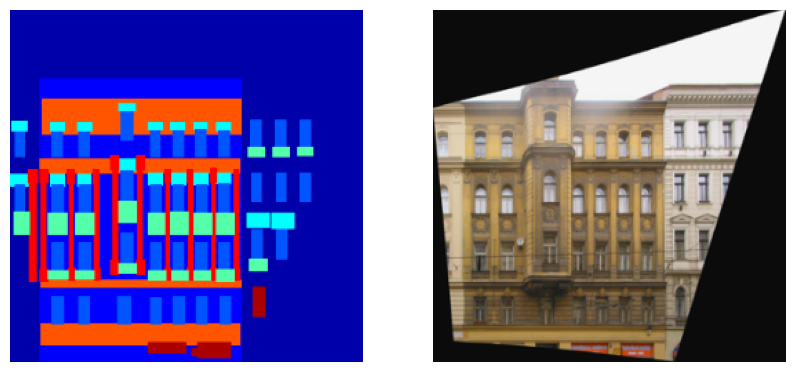

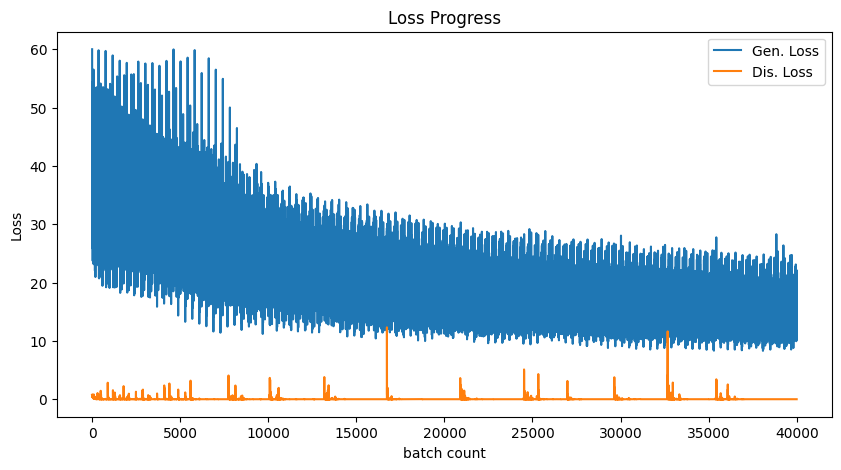

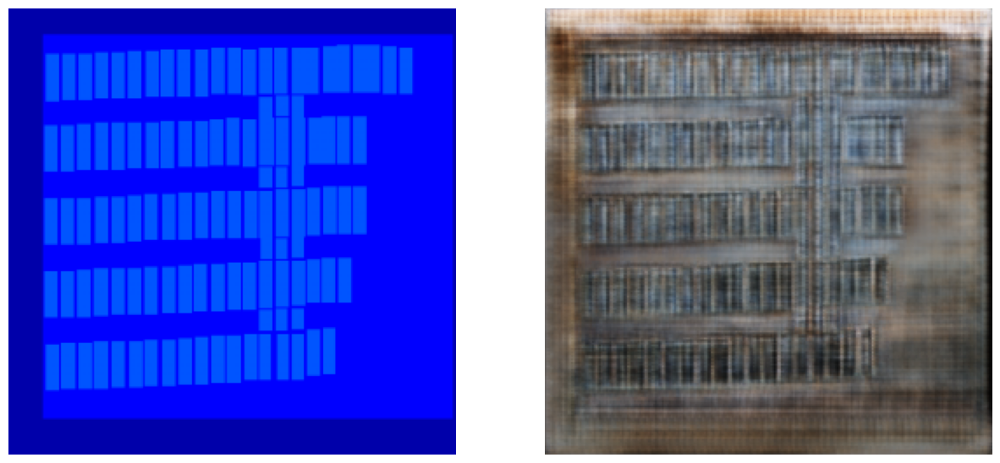

In [ ]:
from os import listdir
from os.path import join
import random
import matplotlib.pyplot as plt
%matplotlib inline

import numpy as np
import os
import time
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
from torchvision.transforms.functional import to_pil_image

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


class FacadeDataset(Dataset):
    def __init__(self, path2img, direction='b2a', transform=False):
        super().__init__()
        self.direction = direction
        self.path2a = join(path2img, 'a')
        self.path2b = join(path2img, 'b')
        self.img_filenames = [x for x in listdir(self.path2a)]
        self.transform = transform

    def __getitem__(self, index):
        a = Image.open(join(self.path2a, self.img_filenames[index])).convert('RGB')
        b = Image.open(join(self.path2b, self.img_filenames[index])).convert('RGB')

        if self.transform:
            a = self.transform(a)
            b = self.transform(b)

        if self.direction == 'b2a':
            return b,a
        else:
            return a,b

    def __len__(self):
        return len(self.img_filenames)

# Image Transform
transform = transforms.Compose([
                    transforms.ToTensor(),
                    transforms.Normalize([0.5,0.5,0.5],[0.5,0.5,0.5]),
                    transforms.Resize((256,256))
])

# Dataset
path2img = '/content/data/facades/train'
path2img_test = '/content/data/facades/test'
train_ds = FacadeDataset(path2img, transform = transform)
test_ds = FacadeDataset(path2img_test, transform = transform)

a,b = train_ds[0]
plt.figure(figsize=(10,10))
plt.subplot(1,2,1)
plt.imshow(to_pil_image(0.5*a+0.5))
plt.axis('off')
plt.subplot(1,2,2)
plt.imshow(to_pil_image(0.5*b+0.5))
plt.axis('off')

train_dl = DataLoader(train_ds, batch_size = 1, shuffle=False)
test_dl = DataLoader(test_ds, batch_size = 1, shuffle = False)

class UNetDown(nn.Module):
    def __init__(self, in_channels, out_channels, normalize=True, dropout=0.0):
        super().__init__()

        layers = [nn.Conv2d(in_channels, out_channels, 4, stride=2, padding=1, bias=False)]

        if normalize:
            layers.append(nn.InstanceNorm2d(out_channels)),

        layers.append(nn.LeakyReLU(0.2))

        if dropout:
            layers.append(nn.Dropout(dropout))

        self.down = nn.Sequential(*layers)

    def forward(self, x):
        x = self.down(x)
        return x

# check
x = torch.randn(16, 3, 256,256, device=device)
model = UNetDown(3,64).to(device)
down_out = model(x)
print(down_out.shape)

class UNetUp(nn.Module):
    def __init__(self, in_channels, out_channels, dropout=0.0):
        super().__init__()

        layers = [
            nn.ConvTranspose2d(in_channels, out_channels,4,2,1,bias=False),
            nn.InstanceNorm2d(out_channels),
            nn.LeakyReLU()
        ]

        if dropout:
            layers.append(nn.Dropout(dropout))

        self.up = nn.Sequential(*layers)

    def forward(self,x,skip):
        x = self.up(x)
        x = torch.cat((x,skip),1)
        return x

# Model Check
x = torch.randn(16, 128, 64, 64, device=device)
model = UNetUp(128,64).to(device)
out = model(x,down_out)
print(out.shape)

# Generator
class GeneratorUNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=3):
        super().__init__()

        self.down1 = UNetDown(in_channels, 64, normalize=False)
        self.down2 = UNetDown(64,128)
        self.down3 = UNetDown(128,256)
        self.down4 = UNetDown(256,512,dropout=0.5)
        self.down5 = UNetDown(512,512,dropout=0.5)
        self.down6 = UNetDown(512,512,dropout=0.5)
        self.down7 = UNetDown(512,512,dropout=0.5)
        self.down8 = UNetDown(512,512,normalize=False,dropout=0.5)

        self.up1 = UNetUp(512,512,dropout=0.5)
        self.up2 = UNetUp(1024,512,dropout=0.5)
        self.up3 = UNetUp(1024,512,dropout=0.5)
        self.up4 = UNetUp(1024,512,dropout=0.5)
        self.up5 = UNetUp(1024,256)
        self.up6 = UNetUp(512,128)
        self.up7 = UNetUp(256,64)
        self.up8 = nn.Sequential(
            nn.ConvTranspose2d(128,3,4,stride=2,padding=1),
            nn.Tanh()
        )

    def forward(self, x):
        d1 = self.down1(x)
        d2 = self.down2(d1)
        d3 = self.down3(d2)
        d4 = self.down4(d3)
        d5 = self.down5(d4)
        d6 = self.down6(d5)
        d7 = self.down7(d6)
        d8 = self.down8(d7)

        u1 = self.up1(d8,d7)
        u2 = self.up2(u1,d6)
        u3 = self.up3(u2,d5)
        u4 = self.up4(u3,d4)
        u5 = self.up5(u4,d3)
        u6 = self.up6(u5,d2)
        u7 = self.up7(u6,d1)
        u8 = self.up8(u7)

        return u8

# check
x = torch.randn(16,3,256,256,device=device)
model = GeneratorUNet().to(device)
out = model(x)
print(out.shape)

class Dis_block(nn.Module):
    def __init__(self, in_channels, out_channels, normalize=True):
        super().__init__()

        layers = [nn.Conv2d(in_channels, out_channels, 3, stride=2, padding=1)]
        if normalize:
            layers.append(nn.InstanceNorm2d(out_channels))
        layers.append(nn.LeakyReLU(0.2))

        self.block = nn.Sequential(*layers)

    def forward(self, x):
        x = self.block(x)
        return x

# check
x = torch.randn(16,64,128,128,device=device)
model = Dis_block(64,128).to(device)
out = model(x)
print(out.shape)

class Discriminator(nn.Module):
    def __init__(self, in_channels=3):
        super().__init__()

        self.stage_1 = Dis_block(in_channels*2,64,normalize=False)
        self.stage_2 = Dis_block(64,128)
        self.stage_3 = Dis_block(128,256)
        self.stage_4 = Dis_block(256,512)

        self.patch = nn.Conv2d(512,1,3,padding=1) # 16x16 patch

    def forward(self,a,b):
        x = torch.cat((a,b),1)
        x = self.stage_1(x)
        x = self.stage_2(x)
        x = self.stage_3(x)
        x = self.stage_4(x)
        x = self.patch(x)
        x = torch.sigmoid(x)
        return x
# check
x = torch.randn(16,3,256,256,device=device)
model = Discriminator().to(device)
out = model(x,x)
print(out.shape)

model_gen = GeneratorUNet().to(device)
model_dis = Discriminator().to(device)

# 가중치 초기화
def initialize_weights(model):
    class_name = model.__class__.__name__
    if class_name.find('Conv') != -1:
        nn.init.normal_(model.weight.data, 0.0, 0.02)


# weighting initialization
model_gen.apply(initialize_weights);
model_dis.apply(initialize_weights);

# loss function
loss_func_gan = nn.BCELoss()
loss_func_pix = nn.L1Loss()

# loss_func_pix weighting
lambda_pixel = 100

# # of patch
patch = (1,256//2**4,256//2**4)

# Optimized Parameter
from torch import optim
lr = 2e-4
beta1 = 0.5
beta2 = 0.999

opt_dis = optim.Adam(model_dis.parameters(),lr=lr,betas=(beta1,beta2))
opt_gen = optim.Adam(model_gen.parameters(),lr=lr,betas=(beta1,beta2))

# model training
model_gen.train()
model_dis.train()

batch_count = 0
num_epochs = 100
start_time = time.time()

loss_hist = {'gen':[],
             'dis':[]}

for epoch in range(num_epochs):
    for a, b in train_dl:
        ba_si = a.size(0)

        # real image
        real_a = a.to(device)
        real_b = b.to(device)

        # patch label
        real_label = torch.ones(ba_si, *patch, requires_grad=False).to(device)
        fake_label = torch.zeros(ba_si, *patch, requires_grad=False).to(device)

        # generator
        model_gen.zero_grad()

        fake_b = model_gen(real_a)
        out_dis = model_dis(fake_b, real_b)

        gen_loss = loss_func_gan(out_dis, real_label)
        pixel_loss = loss_func_pix(fake_b, real_b)

        g_loss = gen_loss + lambda_pixel * pixel_loss
        g_loss.backward()
        opt_gen.step()

        # discriminator
        model_dis.zero_grad()

        out_dis = model_dis(real_b, real_a)
        real_loss = loss_func_gan(out_dis,real_label)

        out_dis = model_dis(fake_b.detach(), real_a)
        fake_loss = loss_func_gan(out_dis,fake_label)

        d_loss = (real_loss + fake_loss) / 2.
        d_loss.backward()
        opt_dis.step()

        loss_hist['gen'].append(g_loss.item())
        loss_hist['dis'].append(d_loss.item())

        batch_count += 1
        if batch_count % 100 == 0:
            print('Epoch: %.0f, G_Loss: %.6f, D_Loss: %.6f, time: %.2f min' %(epoch, g_loss.item(), d_loss.item(), (time.time()-start_time)/60))

# loss history
plt.figure(figsize=(10,5))
plt.title('Loss Progress')
plt.plot(loss_hist['gen'], label='Gen. Loss')
plt.plot(loss_hist['dis'], label='Dis. Loss')
plt.xlabel('batch count')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Saving weight
path2models = './models/'
os.makedirs(path2models, exist_ok=True)
path2weights_gen = os.path.join(path2models, 'weights_gen.pt')
path2weights_dis = os.path.join(path2models, 'weights_dis.pt')

torch.save(model_gen.state_dict(), path2weights_gen)
torch.save(model_dis.state_dict(), path2weights_dis)

# Weight control
weights = torch.load(path2weights_gen)
model_gen.load_state_dict(weights)

# evaluation model
model_gen.eval()

# Image Generating
with torch.no_grad():
    for a,b in test_dl:
        fake_imgs = model_gen(a.to(device)).detach().cpu()
        #plt.savefig('fake_to_real.jpg')
        #real_imgs = b
        real_imgs = a
        break

# Generating Fake to real image
plt.figure(figsize=(15,15))

for ii in range(0,2,2):
    plt.subplot(1,2,ii+1)
    plt.imshow(to_pil_image(0.5*real_imgs[ii]+0.5))
    plt.axis('off')
    plt.subplot(1,2,ii+2)
    plt.imshow(to_pil_image(0.5*fake_imgs[ii]+0.5))
    plt.axis('off')

#### CycleGAN (페어 이미지 입력이 필요없는 네트워크)

논문: https://arxiv.org/pdf/1703.10593.pdf

논문 저자 PyTorch 구현체: https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix/


![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FdRMf9Q%2FbtrFP0rYrPm%2FjhoUiGJWZQ86CgCYjGD5Vk%2Fimg.png)

위 pix2pix는 이미지가 pair로 있어야 가능했다.

본 cycleGAN은 그 부분을 해결함.

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FebFwHB%2FbtrFAiF1KUE%2FDoPJ7Q7hioL2lppiakER60%2Fimg.png)

1. G:A→B  > A영역의 이미지를 B로 바꾸는 generator 네트워크
2. F:B→A  > B영역의 이미지를 A로 바꾸는 generator 네트워크
3. $D_{A}$ > Real A 와 Fake A를 구분하는 discriminator 네트워크
4. $D_{B}$ > Real B 와 Fake B를 구분하는 discriminator 네트워크

- 위 4개의 네트워크가 학습된다.
- Cycle: A 영역의 실제 이미지는 B영역에서 generator 하고 다시 A영역으로 돌려서 reconstruction. B는 반대
- Discriminator는 A영역, B영역에서 real여부 체크(완전히 같지 않아도 되지 reconstruction이 아니니까)


![](https://camo.githubusercontent.com/16fa02525bf502bec1aac77a3eb5b96928b0f25d73f7d9dedcc041ba28c38751/68747470733a2f2f6a756e79616e7a2e6769746875622e696f2f4379636c6547414e2f696d616765732f7465617365725f686967685f7265732e6a7067)

결과가 매우 좋다!

##[5교시]  DDPM: Denoising Diffusion Probabilistic Models

논문: https://proceedings.mlr.press/v37/sohl-dickstein15.html
논문2: https://arxiv.org/abs/2006.11239




##### 1차 Markov Chain

![](https://blog.kakaocdn.net/dn/bScE5e/btqKv6JI80i/zmSECnnygwlHlDaM2bySl0/img.png)





- "1차" = 현재 시점의 변화는 이전시점에만 영향을 받는다
- t=0에서부터 변화를 누적하면 임의 시점 T의 값을 알 수 있다.
- 조건을 만족하는 가운데 t에서 t-1을 예측 할 수 있으면, t=0인 시점까지 알 수 있다.

귀납법?

![](https://i2.ruliweb.com/img/21/02/16/177aa13be9a50db54.jpg)

##### Gaussian 확률 분포

변화를 예측하기 위한 최소한의 조건?
- = 이해 가능하고 표현가능한 데이터라면?
- = 가우시안이라면?
- 변화의 크기가 매우 작을때, 디퓨전 모델의 잡음이 가우시안분포일때 디노이징도 가우시안분포임이 증명되어있음

 - > Feller, W. (1949). On the theory of stochastic processes, with particular reference to applications. Proceedings of the [First] Berkeley Symposium on Mathematical Statistics and Probability, 403–432.







##### Latent variable

- 레이턴트 베리어블이란 "잠재변수". 즉, vae 처럼 원데이터에 숨어있는 정보
- 여기서는 *이미지 그 자체로 레이턴트 베리어블로 가정*



> Q. "생성 = latent variable -> 이미지"
간단한 문제인가요?


![](https://velog.velcdn.com/images/hanlyang0522/post/ff92fb62-7142-4259-9414-ae86a231e671/image.png)


순서대로 동작? 반대로 오는 점선은 뭐지?

> Forward Diffusion Process: 이미지에 고정된(fixed) 정규 분포로 Noise를 생성하여 더해나감
> Reverse Diffusion Process: 이미지를 학습된(learned) 분포로 생성된 Noise이미지.

즉, Diffusion Model이 풀려고 하는 문제는, Forward -> Reverse 단계를 거친 '결과 이미지'를 '입력 이미지'의 확률 분포와 유사하게 만드는 것 입니다. 이를 위해 Reverse단계에서, Noise 생성 확률 분포 Parameter인 평균과 표준편차를 업데이트하며 학습이 진행됨.


![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FETLeE%2Fbtr6bu1KNlU%2FoRi4IGQcMyXOA1Bcc2HUSK%2Fimg.png)

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FbNdTuO%2Fbtr7hyWZlYB%2FuVb00KNWNLuDVSnDUbzJr1%2Fimg.png)

1. Training: Loss를 줄이는 것 = 실제 주입된 에러를 모델이 맞추는 것
2. Sampling: 끝(T: 완벽한 잡음)에서 시작(t=0: 원본)을 복원해나감


ref: https://developer.nvidia.com/blog/improving-diffusion-models-as-an-alternative-to-gans-part-1/

ref2: https://medium.com/@steinsfu/diffusion-model-clearly-explained-cd331bd41166

https://colab.research.google.com/drive/1AZ2_BAwXrU8InE_qAE9cFZ0lsIO5a_xp?usp=sharing#scrollTo=rbicqEzLjinX

#### 세팅!

**einops** 사용!


코드 옵션:

- `no_train`: True인 경우, pre-trained 모델 사용

- `fashion`: Fashion-MNIST dataset 쓸거면 (`True`)

- `batch_size`, `n_epochs` and `lr(default=0.001 in paper)`

In [ ]:
!pip3 install --upgrade pip
!pip3 install einops

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 25.3 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 22.0.4
    Uninstalling pip-22.0.4:
      Successfully uninstalled pip-22.0.4
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.6/41.6 kB 594.4 kB/s eta 0:00:00


In [ ]:
# Import of libraries
import random
import imageio
import numpy as np
from argparse import ArgumentParser

from tqdm.auto import tqdm
import matplotlib.pyplot as plt

import einops
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import DataLoader

from torchvision.transforms import Compose, ToTensor, Lambda
from torchvision.datasets.mnist import MNIST, FashionMNIST

# Setting reproducibility
SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Definitions
STORE_PATH_MNIST = f"ddpm_model_mnist.pt"
STORE_PATH_FASHION = f"ddpm_model_fashion.pt"

no_train = False
fashion = True
batch_size = 128
n_epochs = 20
lr = 0.001

store_path = "ddpm_fashion.pt" if fashion else "ddpm_mnist.pt"

#### Loading data

Fashion-MNIST 사용.

> ***주의***: 이미지를 `[-1,1]` 범위로 normalization해야함.  (보통은 `[0,1]`).  DDPM network가 denoising process에서 정규분포를 가정한 에러를 추정하므로

In [ ]:
# Loading the data (converting each image into a tensor and normalizing between [-1, 1])
transform = Compose([
    ToTensor(),
    Lambda(lambda x: (x - 0.5) * 2)]    #### 이부분!!!
)
ds_fn = FashionMNIST if fashion else MNIST
dataset = ds_fn("./datasets", download=True, train=True, transform=transform)
loader = DataLoader(dataset, batch_size, shuffle=True)

  0%|          | 0/26421880 [00:00<?, ?it/s]

Extracting ./datasets/FashionMNIST/raw/train-images-idx3-ubyte.gz to ./datasets/FashionMNIST/raw



  0%|          | 0/29515 [00:00<?, ?it/s]

Extracting ./datasets/FashionMNIST/raw/train-labels-idx1-ubyte.gz to ./datasets/FashionMNIST/raw



  0%|          | 0/4422102 [00:00<?, ?it/s]

Extracting ./datasets/FashionMNIST/raw/t10k-images-idx3-ubyte.gz to ./datasets/FashionMNIST/raw



  0%|          | 0/5148 [00:00<?, ?it/s]

Extracting ./datasets/FashionMNIST/raw/t10k-labels-idx1-ubyte.gz to ./datasets/FashionMNIST/raw



In [ ]:
def show_images(images, title=""):
    """Shows the provided images as sub-pictures in a square"""

    # Converting images to CPU numpy arrays
    if type(images) is torch.Tensor:
        images = images.detach().cpu().numpy()

    # Defining number of rows and columns
    fig = plt.figure(figsize=(8, 8))
    rows = int(len(images) ** (1 / 2))
    cols = round(len(images) / rows)

    # Populating figure with sub-plots
    idx = 0
    for r in range(rows):
        for c in range(cols):
            fig.add_subplot(rows, cols, idx + 1)

            if idx < len(images):
                plt.imshow(images[idx][0], cmap="gray")
                idx += 1
    fig.suptitle(title, fontsize=30)

    # Showing the figure
    plt.show()

In [ ]:
def show_first_batch(loader):
    for batch in loader:
        show_images(batch[0], "Images in the first batch")
        break

<ipython-input-5-41ca7b27e20f>:17: MatplotlibDeprecationWarning: Adding an axes using the same arguments as a previous axes currently reuses the earlier instance.  In a future version, a new instance will always be created and returned.  Meanwhile, this warning can be suppressed, and the future behavior ensured, by passing a unique label to each axes instance.
  fig.add_subplot(rows, cols, idx + 1)


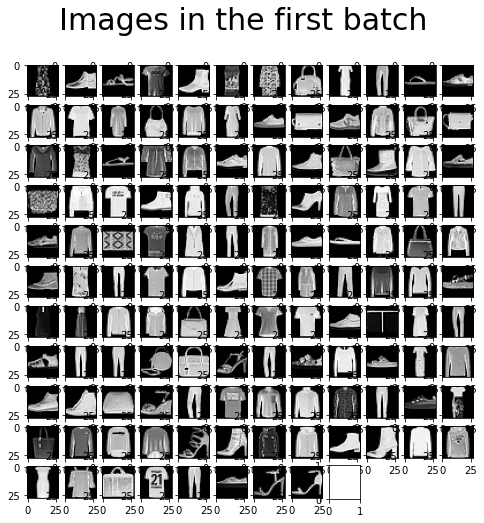

In [ ]:
# Optionally, show a batch of regular images
show_first_batch(loader)

#### Defining the DDPM module


![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FbhlrrF%2Fbtr7pStFyZd%2FNqxQ6kHp9n1PCBzLkOH031%2Fimg.png)



- `n_steps`: number of diffusion steps $T$; 얼마나 많은 단계를 통해 가공할 것인가?
- `min_beta`: value of the first $\beta_t$ ($\beta_1$);
- `max_beta`: value of the last  $\beta_t$ ($\beta_T$);
- `device`: device onto which the model is run;
- `image_chw`: tuple contining dimensionality of images.



![](https://paramhanji.github.io/files/images/ddpm/ddpm.png)

- Forward path: `show_forward`
 - ***학습의 대상이 아님***: 잡음을 더해 나가는 단계 (단순 스케쥴러로 모든 픽셀에 더해지는 형태로 작업됨)

 - $q(x_t | x_{t-1})$: 1차 markov chain 가정에 따라 원래 이미지 각 픽셀 값을 줄이고, random 값을 주입하는 것.

 - 실제로 random 값에 $β_{i}$를 곱하여 더한다. (누적 곱의 형태로 표현가능하므로, 실제로 step-by-step으로 계산할 필요는 없다)


- Backward path: `generate_new_images`
  - $q(x_{t-1} |x_t)$: 구하고 싶은 것은 이것이나 쉽게 계산되는 것이 아님 = 데이터에 기반하여 러닝하자! (때려 맞추자) = $p_{Θ}(x_{t-1} |x_t)$
  - $p_{Θ}(x_{t-1} |x_t)$: $𝒩$ 즉, 매 순간 픽셀 마다 정규분포(평균, 표준편차)를 추정하게 하자 = 모델. 학습의 목표
  
  - (https://arxiv.org/pdf/2006.11239.pdf) by Ho et. al., two options are considered for $\sigma_t^2$:
    - $\sigma_t^2$ = $\beta_t$
    - $\sigma_t^2$ = $\frac{1 - \bar{\alpha_{t-1}}}{1 - \bar{\alpha_{t}}} \beta_t$





In [ ]:
# Getting device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}\t" + (f"{torch.cuda.get_device_name(0)}" if torch.cuda.is_available() else "CPU"))

In [ ]:
# DDPM class
class MyDDPM(nn.Module):
    def __init__(self, network, n_steps=200, min_beta=10 ** -4, max_beta=0.02, device=None, image_chw=(1, 28, 28)):
        super().__init__()
        self.n_steps = n_steps
        self.device = device
        self.image_chw = image_chw
        self.network = network.to(device)

        # linear 하게 증가하는 beta (더해지는 잡음의 크기)
        self.betas = torch.linspace(min_beta, max_beta, n_steps).to(device)
        # beta로부터 결정되는 alpha와 alpha_bars(누적 곱의 형태)
        self.alphas = 1 - self.betas
        self.alpha_bars = torch.tensor([torch.prod(self.alphas[:i + 1]) for i in range(len(self.alphas))]).to(device)

    def forward(self, x0, t, eta=None):
        # Make input image more noisy (we can directly skip to the desired step)
        n, c, h, w = x0.shape
        a_bar = self.alpha_bars[t]

        if eta is None:
            eta = torch.randn(n, c, h, w).to(self.device)

        noisy = a_bar.sqrt().reshape(n, 1, 1, 1) * x0 + (1 - a_bar).sqrt().reshape(n, 1, 1, 1) * eta
        return noisy

    def backward(self, x, t):
        # Run each image through the network for each timestep t in the vector t.
        # The network returns its estimation of the noise that was added.
        return self.network(x, t)

In [ ]:
def show_forward(ddpm, loader, device):
    # Showing the forward process
    for batch in loader:
        imgs = batch[0]

        show_images(imgs, "Original images")

        for percent in [0.25, 0.5, 0.75, 1]:
            show_images(
                ddpm(imgs.to(device),
                     [int(percent * ddpm.n_steps) - 1 for _ in range(len(imgs))]),
                f"DDPM Noisy images {int(percent * 100)}%"
            )
        break

In [ ]:
def generate_new_images(ddpm, n_samples=16, device=None, frames_per_gif=100, gif_name="sampling.gif", c=1, h=28, w=28):
    """Given a DDPM model, a number of samples to be generated and a device, returns some newly generated samples"""
    frame_idxs = np.linspace(0, ddpm.n_steps, frames_per_gif).astype(np.uint)
    frames = []

    with torch.no_grad():
        if device is None:
            device = ddpm.device

        # Starting from random noise
        x = torch.randn(n_samples, c, h, w).to(device)

        for idx, t in enumerate(list(range(ddpm.n_steps))[::-1]):
            # Estimating noise to be removed
            time_tensor = (torch.ones(n_samples, 1) * t).to(device).long()
            eta_theta = ddpm.backward(x, time_tensor)

            alpha_t = ddpm.alphas[t]
            alpha_t_bar = ddpm.alpha_bars[t]

            # Partially denoising the image
            x = (1 / alpha_t.sqrt()) * (x - (1 - alpha_t) / (1 - alpha_t_bar).sqrt() * eta_theta)

            if t > 0:
                z = torch.randn(n_samples, c, h, w).to(device)

                # Option 1: sigma_t squared = beta_t
                beta_t = ddpm.betas[t]
                sigma_t = beta_t.sqrt()

                # Option 2: sigma_t squared = beta_tilda_t
                # prev_alpha_t_bar = ddpm.alpha_bars[t-1] if t > 0 else ddpm.alphas[0]
                # beta_tilda_t = ((1 - prev_alpha_t_bar)/(1 - alpha_t_bar)) * beta_t
                # sigma_t = beta_tilda_t.sqrt()

                # Adding some more noise like in Langevin Dynamics fashion
                x = x + sigma_t * z

            # Adding frames to the GIF
            if idx in frame_idxs or t == 0:
                # Putting digits in range [0, 255]
                normalized = x.clone()
                for i in range(len(normalized)):
                    normalized[i] -= torch.min(normalized[i])
                    normalized[i] *= 255 / torch.max(normalized[i])

                # Reshaping batch (n, c, h, w) to be a (as much as it gets) square frame
                frame = einops.rearrange(normalized, "(b1 b2) c h w -> (b1 h) (b2 w) c", b1=int(n_samples ** 0.5))
                frame = frame.cpu().numpy().astype(np.uint8)

                # Rendering frame
                frames.append(frame)

    # Storing the gif
    with imageio.get_writer(gif_name, mode="I") as writer:
        for idx, frame in enumerate(frames):
            writer.append_data(frame)
            if idx == len(frames) - 1:
                for _ in range(frames_per_gif // 3):
                    writer.append_data(frames[-1])
    return x

#### UNet architecture


Loss function: $||\epsilon - \epsilon_\theta(\sqrt{\bar{\alpha}_t}x_0 + \sqrt{1 - \bar{\alpha}_t}\epsilon, t)||^2$
> $\epsilon$는 랜덤 noise, $\epsilon_\theta$는 t번째 시점에 모델이 예상해낸 noise

> 위 모델을 살펴보면, 원본($x_0$)과 시점(t)만 영향을 받기 때문에 실제로는 각 시점에 대한 모든 모델 계산은 필요없음.

> 자세한 수식전개: https://xoft.tistory.com/33




Q. SiLU?

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FJXD56%2FbtrXIoCRwjX%2Fq0CKKBs0vYsxvLvUckc3Z0%2Fimg.png)
![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FbpYveq%2FbtrXHSxHDZ5%2FeUbdPEmkksstoObkkX9rcK%2Fimg.png)

In [ ]:
def sinusoidal_embedding(n, d):
    # Returns the standard positional embedding
    embedding = torch.zeros(n, d)
    wk = torch.tensor([1 / 10_000 ** (2 * j / d) for j in range(d)])
    wk = wk.reshape((1, d))
    t = torch.arange(n).reshape((n, 1))
    embedding[:,::2] = torch.sin(t * wk[:,::2])
    embedding[:,1::2] = torch.cos(t * wk[:,::2])

    return embedding

In [ ]:
class MyBlock(nn.Module):
    def __init__(self, shape, in_c, out_c, kernel_size=3, stride=1, padding=1, activation=None, normalize=True):
        super(MyBlock, self).__init__()
        self.ln = nn.LayerNorm(shape)
        self.conv1 = nn.Conv2d(in_c, out_c, kernel_size, stride, padding)
        self.conv2 = nn.Conv2d(out_c, out_c, kernel_size, stride, padding)
        self.activation = nn.SiLU() if activation is None else activation
        self.normalize = normalize

    def forward(self, x):
        out = self.ln(x) if self.normalize else x
        out = self.conv1(out)
        out = self.activation(out)
        out = self.conv2(out)
        out = self.activation(out)
        return out

In [ ]:
class MyUNet(nn.Module):
    def __init__(self, n_steps=1000, time_emb_dim=100):
        super(MyUNet, self).__init__()

        # Sinusoidal embedding
        self.time_embed = nn.Embedding(n_steps, time_emb_dim)
        self.time_embed.weight.data = sinusoidal_embedding(n_steps, time_emb_dim)
        self.time_embed.requires_grad_(False)

        # First half
        self.te1 = self._make_te(time_emb_dim, 1)
        self.b1 = nn.Sequential(
            MyBlock((1, 28, 28), 1, 10),
            MyBlock((10, 28, 28), 10, 10),
            MyBlock((10, 28, 28), 10, 10)
        )
        self.down1 = nn.Conv2d(10, 10, 4, 2, 1)

        self.te2 = self._make_te(time_emb_dim, 10)
        self.b2 = nn.Sequential(
            MyBlock((10, 14, 14), 10, 20),
            MyBlock((20, 14, 14), 20, 20),
            MyBlock((20, 14, 14), 20, 20)
        )
        self.down2 = nn.Conv2d(20, 20, 4, 2, 1)

        self.te3 = self._make_te(time_emb_dim, 20)
        self.b3 = nn.Sequential(
            MyBlock((20, 7, 7), 20, 40),
            MyBlock((40, 7, 7), 40, 40),
            MyBlock((40, 7, 7), 40, 40)
        )
        self.down3 = nn.Sequential(
            nn.Conv2d(40, 40, 2, 1),
            nn.SiLU(),
            nn.Conv2d(40, 40, 4, 2, 1)
        )

        # Bottleneck
        self.te_mid = self._make_te(time_emb_dim, 40)
        self.b_mid = nn.Sequential(
            MyBlock((40, 3, 3), 40, 20),
            MyBlock((20, 3, 3), 20, 20),
            MyBlock((20, 3, 3), 20, 40)
        )

        # Second half
        self.up1 = nn.Sequential(
            nn.ConvTranspose2d(40, 40, 4, 2, 1),
            nn.SiLU(),
            nn.ConvTranspose2d(40, 40, 2, 1)
        )

        self.te4 = self._make_te(time_emb_dim, 80)
        self.b4 = nn.Sequential(
            MyBlock((80, 7, 7), 80, 40),
            MyBlock((40, 7, 7), 40, 20),
            MyBlock((20, 7, 7), 20, 20)
        )

        self.up2 = nn.ConvTranspose2d(20, 20, 4, 2, 1)
        self.te5 = self._make_te(time_emb_dim, 40)
        self.b5 = nn.Sequential(
            MyBlock((40, 14, 14), 40, 20),
            MyBlock((20, 14, 14), 20, 10),
            MyBlock((10, 14, 14), 10, 10)
        )

        self.up3 = nn.ConvTranspose2d(10, 10, 4, 2, 1)
        self.te_out = self._make_te(time_emb_dim, 20)
        self.b_out = nn.Sequential(
            MyBlock((20, 28, 28), 20, 10),
            MyBlock((10, 28, 28), 10, 10),
            MyBlock((10, 28, 28), 10, 10, normalize=False)
        )

        self.conv_out = nn.Conv2d(10, 1, 3, 1, 1)

    def forward(self, x, t):
        # x is (N, 2, 28, 28) (image with positional embedding stacked on channel dimension)
        t = self.time_embed(t)
        n = len(x)
        out1 = self.b1(x + self.te1(t).reshape(n, -1, 1, 1))  # (N, 10, 28, 28)
        out2 = self.b2(self.down1(out1) + self.te2(t).reshape(n, -1, 1, 1))  # (N, 20, 14, 14)
        out3 = self.b3(self.down2(out2) + self.te3(t).reshape(n, -1, 1, 1))  # (N, 40, 7, 7)

        out_mid = self.b_mid(self.down3(out3) + self.te_mid(t).reshape(n, -1, 1, 1))  # (N, 40, 3, 3)

        out4 = torch.cat((out3, self.up1(out_mid)), dim=1)  # (N, 80, 7, 7)
        out4 = self.b4(out4 + self.te4(t).reshape(n, -1, 1, 1))  # (N, 20, 7, 7)

        out5 = torch.cat((out2, self.up2(out4)), dim=1)  # (N, 40, 14, 14)
        out5 = self.b5(out5 + self.te5(t).reshape(n, -1, 1, 1))  # (N, 10, 14, 14)

        out = torch.cat((out1, self.up3(out5)), dim=1)  # (N, 20, 28, 28)
        out = self.b_out(out + self.te_out(t).reshape(n, -1, 1, 1))  # (N, 1, 28, 28)

        out = self.conv_out(out)

        return out

    def _make_te(self, dim_in, dim_out):
        return nn.Sequential(
            nn.Linear(dim_in, dim_out),
            nn.SiLU(),
            nn.Linear(dim_out, dim_out)
        )

In [ ]:
# Defining model
n_steps, min_beta, max_beta = 1000, 10 ** -4, 0.02  # Originally used by the authors
ddpm = MyDDPM(MyUNet(n_steps), n_steps=n_steps, min_beta=min_beta, max_beta=max_beta, device=device)

In [ ]:
sum([p.numel() for p in ddpm.parameters()])

606852

#### Forward example

In [ ]:
# Optionally, load a pre-trained model that will be further trained
# ddpm.load_state_dict(torch.load(store_path, map_location=device))

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:17: MatplotlibDeprecationWarning: Adding an axes using the same arguments as a previous axes currently reuses the earlier instance.  In a future version, a new instance will always be created and returned.  Meanwhile, this warning can be suppressed, and the future behavior ensured, by passing a unique label to each axes instance.


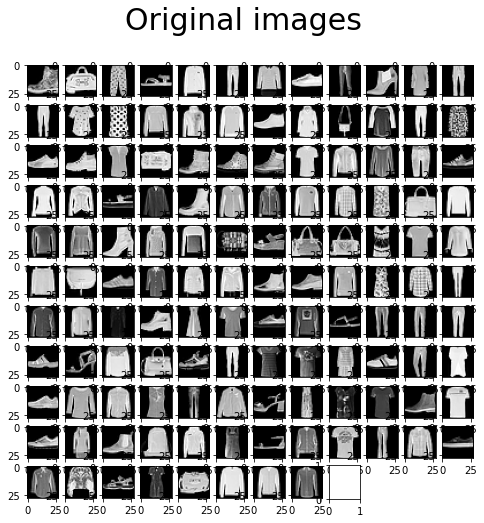

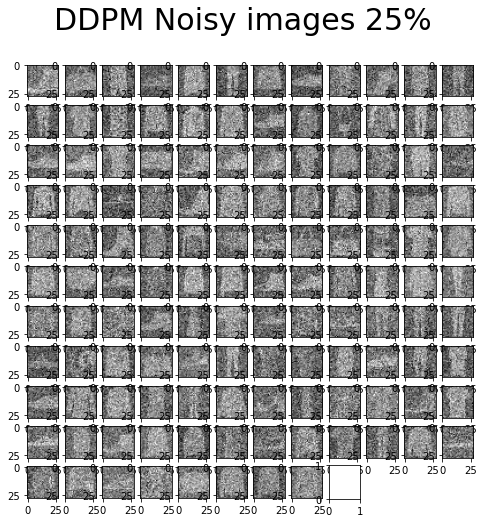

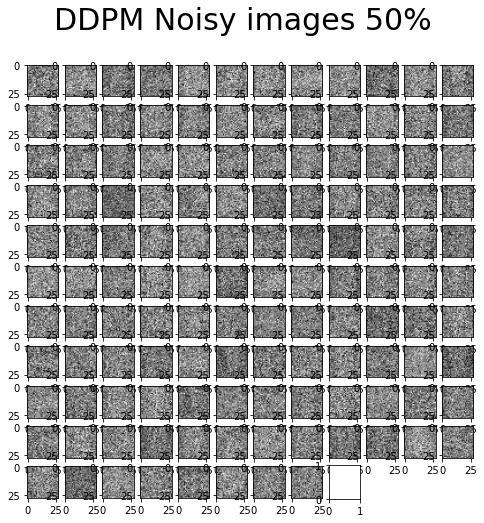

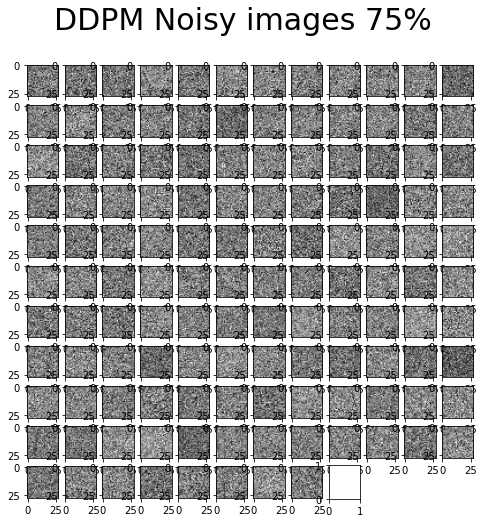

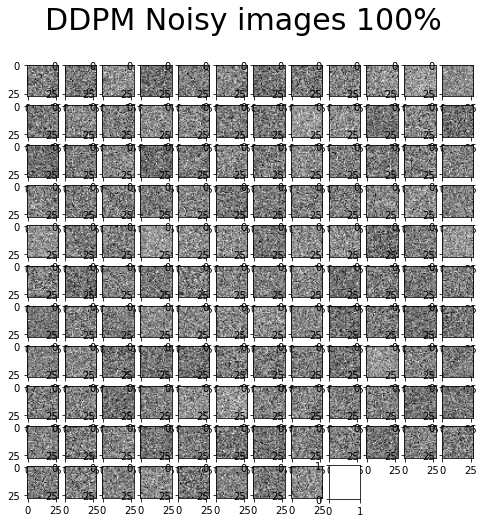

In [ ]:
# Optionally, show the diffusion (forward) process
show_forward(ddpm, loader, device)

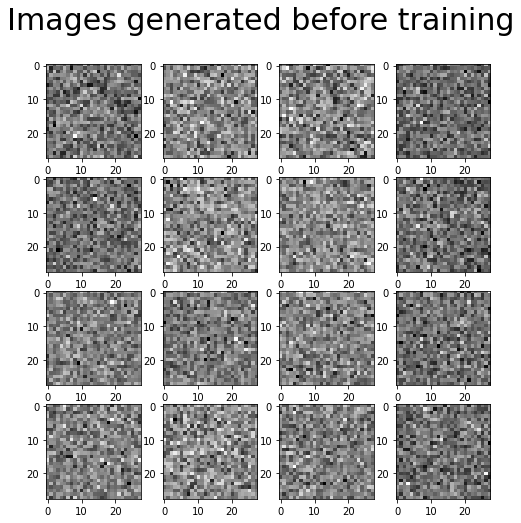

In [ ]:
# Optionally, show the denoising (backward) process
generated = generate_new_images(ddpm, gif_name="before_training.gif")
show_images(generated, "Images generated before training")

#### Training loop

With each batch of our dataset, we run the forward process on the batch.
- `(N, C, H, W)` batch: 각 배치마다 N장의 이미지가 있음, forward process를 수행.
- $t$: time-step, 단 이걸 0~N random int로 지정. 모두 다른 길이로 학습시킨다. (stability를 확보하기 위함. 이미지마다 복잡도가 다르니 최적의 step은 알 수 없자나요?)
- $\epsilon$: The added noise is a `(N, C, H, W)`  


Mean-Squared Error (MSE) loss: 포워드 과정을 통해 noisy images 만들면, $\epsilon$을 찾고자 함. 즉, 해당 step에서 삽입되었던 noise와 예측 값을 같게 만들도록 학습)

In [ ]:
def training_loop(ddpm, loader, n_epochs, optim, device, display=False, store_path="ddpm_model.pt"):
    mse = nn.MSELoss()
    best_loss = float("inf")
    n_steps = ddpm.n_steps

    for epoch in tqdm(range(n_epochs), desc=f"Training progress", colour="#00ff00"):
        epoch_loss = 0.0
        for step, batch in enumerate(tqdm(loader, leave=False, desc=f"Epoch {epoch + 1}/{n_epochs}", colour="#005500")):
            # Loading data
            x0 = batch[0].to(device)
            n = len(x0)

            # Picking some noise for each of the images in the batch, a timestep and the respective alpha_bars
            eta = torch.randn_like(x0).to(device)
            t = torch.randint(0, n_steps, (n,)).to(device)

            # Computing the noisy image based on x0 and the time-step (forward process)
            noisy_imgs = ddpm(x0, t, eta)

            # Getting model estimation of noise based on the images and the time-step
            eta_theta = ddpm.backward(noisy_imgs, t.reshape(n, -1))

            # Optimizing the MSE between the noise plugged and the predicted noise
            loss = mse(eta_theta, eta)
            optim.zero_grad()
            loss.backward()
            optim.step()

            epoch_loss += loss.item() * len(x0) / len(loader.dataset)

        # Display images generated at this epoch
        if display:
            show_images(generate_new_images(ddpm, device=device), f"Images generated at epoch {epoch + 1}")

        log_string = f"Loss at epoch {epoch + 1}: {epoch_loss:.3f}"

        # Storing the model
        if best_loss > epoch_loss:
            best_loss = epoch_loss
            torch.save(ddpm.state_dict(), store_path)
            log_string += " --> Best model ever (stored)"

        print(log_string)

In [ ]:
# Training
store_path = "ddpm_fashion.pt" if fashion else "ddpm_mnist.pt"
if not no_train:
    training_loop(ddpm, loader, n_epochs, optim=Adam(ddpm.parameters(), lr), device=device, store_path=store_path)

Training progress:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 1/20:   0%|          | 0/469 [00:00<?, ?it/s]

Loss at epoch 1: 0.206 --> Best model ever (stored)


Epoch 2/20:   0%|          | 0/469 [00:00<?, ?it/s]

Loss at epoch 2: 0.081 --> Best model ever (stored)


...

Loss at epoch 18: 0.050 --> Best model ever (stored)


Epoch 19/20:   0%|          | 0/469 [00:00<?, ?it/s]

Loss at epoch 19: 0.049 --> Best model ever (stored)


Epoch 20/20:   0%|          | 0/469 [00:00<?, ?it/s]

Loss at epoch 20: 0.049 --> Best model ever (stored)


#### 학습 결과


In [ ]:
# Loading the trained model
best_model = MyDDPM(MyUNet(), n_steps=n_steps, device=device)
best_model.load_state_dict(torch.load(store_path, map_location=device))
best_model.eval()
print("Model loaded")

Model loaded: Generating new images


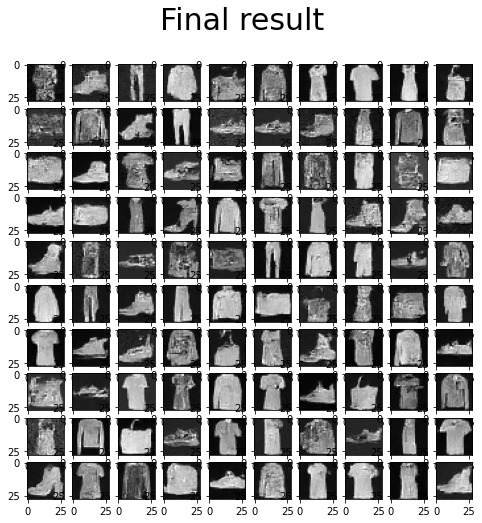

In [ ]:
print("Generating new images")
generated = generate_new_images(
        best_model,
        n_samples=100,
        device=device,
        gif_name="fashion.gif" if fashion else "mnist.gif"
    )
show_images(generated, "Final result")

#### Visualizing the diffusion

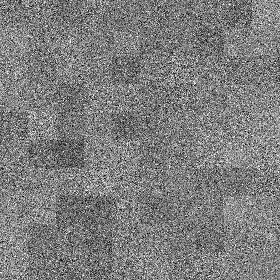

In [ ]:
from IPython.display import Image

Image(open('fashion.gif' if fashion else 'mnist.gif','rb').read())